In [1]:
from __future__ import annotations

import matplotlib.pyplot as plt
import pandas as pd
import scanpy as sc
import os
import shutil
import re
import numpy as np
import anndata as ad
import pooch

In [2]:
os.getcwd()

'GSE207654-Single-Cell-Reprogramming-Analysis\\notebooks'

In [3]:
os.chdir("../data")  # data folder of this repository

In [8]:
print(os.getcwd())

GSE207654-Single-Cell-Reprogramming-Analysis\data


In [9]:
fs = [os.path.join('GSE207654', f) for f in os.listdir('GSE207654') if 'genes' in f]
print(fs)
samples1 = fs

['GSE207654\\GSM6304413_EB_D0.genes.tsv.gz', 'GSE207654\\GSM6304414_iMK_D3.genes.tsv.gz', 'GSE207654\\GSM6304415_iMK_D5.genes.tsv.gz', 'GSE207654\\GSM6304416_iMK_D7.genes.tsv.gz']


In [10]:
samples2 = [re.findall(r'GSM\d+', f)[0] for f in fs]
print(samples2)

['GSM6304413', 'GSM6304414', 'GSM6304415', 'GSM6304416']


In [11]:
sample_to_file = {}
 
for filepath in samples1:
    # Extract the sample ID from the file path, in the same format as samples2
    # Match 'GSM' + digits with a regular expression, e.g. GSM12345
    match = re.findall(r'GSM\d+', filepath)
    if match:
        sample_id = match[0]
        sample_to_file[sample_id] = filepath
 
print(sample_to_file)

{'GSM6304413': 'GSE207654\\GSM6304413_EB_D0.genes.tsv.gz', 'GSM6304414': 'GSE207654\\GSM6304414_iMK_D3.genes.tsv.gz', 'GSM6304415': 'GSE207654\\GSM6304415_iMK_D5.genes.tsv.gz', 'GSM6304416': 'GSE207654\\GSM6304416_iMK_D7.genes.tsv.gz'}


In [12]:
# Create the outputs folder (if it does not exist)
os.makedirs('outputs', exist_ok=True)
 
# Loop over samples2 and copy the files of each sample ID
for sample_id in samples2:
    if sample_id not in sample_to_file:
        print(f"Warning: no files found for sample {sample_id}!")
        continue
 
    y = sample_to_file[sample_id]
 
    output_dir = os.path.join('outputs', sample_id)
    os.makedirs(output_dir, exist_ok=True)
 
    # Copy and rename the features file
    shutil.copy(y, os.path.join(output_dir, 'genes.tsv.gz'))
 
    # Build the matching matrix file name and copy it
    matrix_file = y.replace('genes', 'matrix').replace('.tsv', '.mtx')
    shutil.copy(matrix_file, os.path.join(output_dir, 'matrix.mtx.gz'))
 
    # Build the matching barcodes file name and copy it
    barcodes_file = y.replace('genes', 'barcodes')
    shutil.copy(barcodes_file, os.path.join(output_dir, 'barcodes.tsv.gz'))

In [13]:
np.random.seed(42)  # or any other number you choose

In [14]:
sc.settings.set_figure_params(dpi=100, facecolor="white")

In [15]:
os.makedirs("1-DataPre",exist_ok=True)

In [16]:
os.getcwd()

'GSE207654-Single-Cell-Reprogramming-Analysis\\data'

In [17]:
samples = [s for s in os.listdir('./outputs') if not s.startswith('.')]
samples

['GSM6304413', 'GSM6304414', 'GSM6304415', 'GSM6304416']

# 2. Preprocessing and Quality Control 

#### A. removal of low expression genes, cell quality control, filtration and expression count normalization.
For datasets with multiple batches, we carried out partial quality control at the time of reading (the paper did not mention specific filtering parameters, we chose common parameters)


In [18]:
import scanpy as sc
import os
import gzip
import pandas as pd
from scipy.io import mmread

def read_old_10x_mtx(sample_path, var_names='gene_symbols'):
    """
    Manually read legacy 10x data (genes.tsv.gz format)
    """
    # File paths
    matrix_path = os.path.join(sample_path, 'matrix.mtx.gz')
    genes_path = os.path.join(sample_path, 'genes.tsv.gz')
    barcodes_path = os.path.join(sample_path, 'barcodes.tsv.gz')
    
    # Read the expression matrix
    expr_matrix = mmread(matrix_path).tocsr()
    
    # Read gene information (legacy genes.tsv.gz has two columns: ENSG ID + gene name)
    with gzip.open(genes_path, 'rt') as f:
        genes = pd.read_csv(f, sep='\t', header=None, names=['ensembl_id', 'gene_symbol'])
    
    # Read barcode information
    with gzip.open(barcodes_path, 'rt') as f:
        barcodes = pd.read_csv(f, sep='\t', header=None, names=['barcode'])
    
    # Create the AnnData object
    adata = sc.AnnData(X=expr_matrix.T)  # Note the transpose: in scanpy rows are cells and columns are genes
    adata.obs_names = barcodes['barcode'].values
    adata.var_names = genes['gene_symbol'].values if var_names == 'gene_symbols' else genes['ensembl_id'].values
    adata.var['ensembl_id'] = genes['ensembl_id'].values  # Keep the ENSG IDs
    
    return adata

# Main loop
sce_list = []
dir_path = 'outputs'  # outputs folder created above (relative to data/)
samples = [d for d in os.listdir(dir_path) if os.path.isdir(os.path.join(dir_path, d))]

for s in samples:
    sample_path = os.path.join(dir_path, s)
    print(f"\n===== Processing sample: {s} =====")
    print(f"Sample path: {sample_path}")

    # For datasets with multiple batches, QC is done separately for each sample
    try:
        # Read legacy data with the custom function
        adata = read_old_10x_mtx(sample_path, var_names='gene_symbols')
        
        # Handle duplicated gene names (if any)
        adata.var_names_make_unique()
        
        # Quality filtering: genes in at least 5 cells, cells with at least 300 genes (min.cells and min.features)
        sc.pp.filter_genes(adata, min_cells=5)
        sc.pp.filter_cells(adata, min_genes=300)
        adata.obs['project'] = s
        
        sce_list.append(adata)
        print(f"✅ Sample {s} processed: {adata.n_obs} cells, {adata.n_vars} genes")
        
    except Exception as e:
        print(f"❌ Failed to read sample {s}: {str(e)[:200]}")

print(f"\nSamples processed successfully: {len(sce_list)}")


===== Processing sample: GSM6304413 =====
Sample path: outputs\GSM6304413
✅ Sample GSM6304413 processed: 11752 cells, 18270 genes

===== Processing sample: GSM6304414 =====
Sample path: outputs\GSM6304414
✅ Sample GSM6304414 processed: 19428 cells, 18341 genes

===== Processing sample: GSM6304415 =====
Sample path: outputs\GSM6304415
✅ Sample GSM6304415 processed: 9128 cells, 18844 genes

===== Processing sample: GSM6304416 =====
Sample path: outputs\GSM6304416
✅ Sample GSM6304416 processed: 10603 cells, 18465 genes

Samples processed successfully: 4


In [19]:
sce_list

[AnnData object with n_obs × n_vars = 11752 × 18270
     obs: 'n_genes', 'project'
     var: 'ensembl_id', 'n_cells',
 AnnData object with n_obs × n_vars = 19428 × 18341
     obs: 'n_genes', 'project'
     var: 'ensembl_id', 'n_cells',
 AnnData object with n_obs × n_vars = 9128 × 18844
     obs: 'n_genes', 'project'
     var: 'ensembl_id', 'n_cells',
 AnnData object with n_obs × n_vars = 10603 × 18465
     obs: 'n_genes', 'project'
     var: 'ensembl_id', 'n_cells']

In [20]:
adata = sc.concat(sce_list,label="sampleid",index_unique='_')
adata.obs_names_make_unique

<bound method AnnData.obs_names_make_unique of AnnData object with n_obs × n_vars = 50911 × 16437
    obs: 'n_genes', 'project', 'sampleid'>

In [16]:
#pip install array-api-compat

In [21]:
adata.write('./1-DataPre/GSE188711.h5ad')

In [22]:
os.chdir("./1-DataPre/")
os.getcwd()

'GSE207654-Single-Cell-Reprogramming-Analysis\\data\\1-DataPre'

In [23]:
adata = sc.read_h5ad("GSE188711.h5ad")

In [24]:
# Add gene annotations to var
# mitochondrial genes, "MT-" for human, "Mt-" for mouse
adata.var["mt"] = adata.var_names.str.startswith("MT-")
# ribosomal genes
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))
# hemoglobin genes
adata.var["hb"] = adata.var_names.str.contains("^HB[^(P)]")

In [25]:
adata.var # metadata of each gene

,mt,ribo,hb
RP11-34P13.7,False,False,False
AL627309.1,False,False,False
AP006222.2,False,False,False
RP4-669L17.10,False,False,False
RP11-206L10.3,False,False,False
...,...,...,...
AC011043.1,False,False,False
AL592183.1,False,False,False
AC011841.1,False,False,False
AL354822.1,False,False,False


In [26]:
adata.obs # metadata of each cell

,n_genes,project,sampleid
AAACCCAAGAAACACT-1_0,5132,GSM6304413,0
AAACCCAAGCAGGGAG-1_0,4846,GSM6304413,0
AAACCCAAGGCTCTAT-1_0,5614,GSM6304413,0
AAACCCAAGTCGCCCA-1_0,5095,GSM6304413,0
AAACCCACACAACGTT-1_0,5344,GSM6304413,0
...,...,...,...
TTTGTTGAGCACTCGC-1_3,3291,GSM6304416,3
TTTGTTGAGTGAGGCT-1_3,2468,GSM6304416,3
TTTGTTGCAACTGGTT-1_3,4402,GSM6304416,3
TTTGTTGCACGCGTCA-1_3,4559,GSM6304416,3


In [27]:
# Compute QC metrics of each cell for the given gene sets
sc.pp.calculate_qc_metrics(
    adata, qc_vars=["mt", "ribo", "hb"], inplace=True, log1p=True
)

In [24]:
adata.var.head()

,mt,ribo,hb,n_cells_by_counts,mean_counts,log1p_mean_counts,pct_dropout_by_counts,total_counts,log1p_total_counts
RP11-34P13.7,False,False,False,279,0.005559,0.005543,99.451985,283,5.648974
AL627309.1,False,False,False,899,0.019367,0.019182,98.234173,986,6.894670
AP006222.2,False,False,False,7202,0.171731,0.158482,85.853745,8743,9.076123
RP4-669L17.10,False,False,False,426,0.008485,0.008450,99.163246,432,6.070738
RP11-206L10.3,False,False,False,2065,0.043173,0.042267,95.943902,2198,7.695758


In [25]:
adata.obs.head()

,n_genes,project,sampleid,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,total_counts_mt,log1p_total_counts_mt,pct_counts_mt,total_counts_ribo,log1p_total_counts_ribo,pct_counts_ribo,total_counts_hb,log1p_total_counts_hb,pct_counts_hb
AAACCCAAGAAACACT-1_0,5132,GSM6304413,0,5125,8.542081,31768,10.366246,38.047721,52.738605,60.331151,69.686477,3398,8.131237,10.696298,10339,9.243775,32.545329,243,5.497168,0.764921
AAACCCAAGCAGGGAG-1_0,4846,GSM6304413,0,4829,8.482602,29628,10.296509,34.035372,48.869313,58.370460,68.992170,2506,7.826842,8.458215,9088,9.114820,30.673687,1121,7.022868,3.783583
AAACCCAAGGCTCTAT-1_0,5614,GSM6304413,0,5607,8.631949,32796,10.398092,25.923893,38.120503,47.990609,60.653738,2665,7.888335,8.125991,7770,8.958154,23.691914,267,5.590987,0.814124
AAACCCAAGTCGCCCA-1_0,5095,GSM6304413,0,5081,8.533460,27414,10.218846,28.113373,41.343839,50.488801,63.073612,2005,7.603898,7.313781,7424,8.912608,27.081053,507,6.230481,1.849420
AAACCCACACAACGTT-1_0,5344,GSM6304413,0,5337,8.582606,28811,10.268547,27.142411,40.564368,50.074624,61.948561,2082,7.641564,7.226407,7562,8.931023,26.246920,576,6.357842,1.999236


In [26]:
#adata.obs['project']=adata.obs['project'].astype('category')  # convert to categorical to save memory
# Map GSM accessions to time points
gsm_to_time = {
    "GSM6304413": "D0",
    "GSM6304414": "D3",
    "GSM6304415": "D5",  # assumed: the next GSM accession is D5; adjust if needed
    "GSM6304416": "D7"   # assumed: the next GSM accession is D7; adjust if needed
}
adata.obs['project'] = adata.obs['project'].map(gsm_to_time)
adata.obs['project'] = adata.obs['project'].astype('category')

<Axes: xlabel='pct_counts_mt', ylabel='Count'>

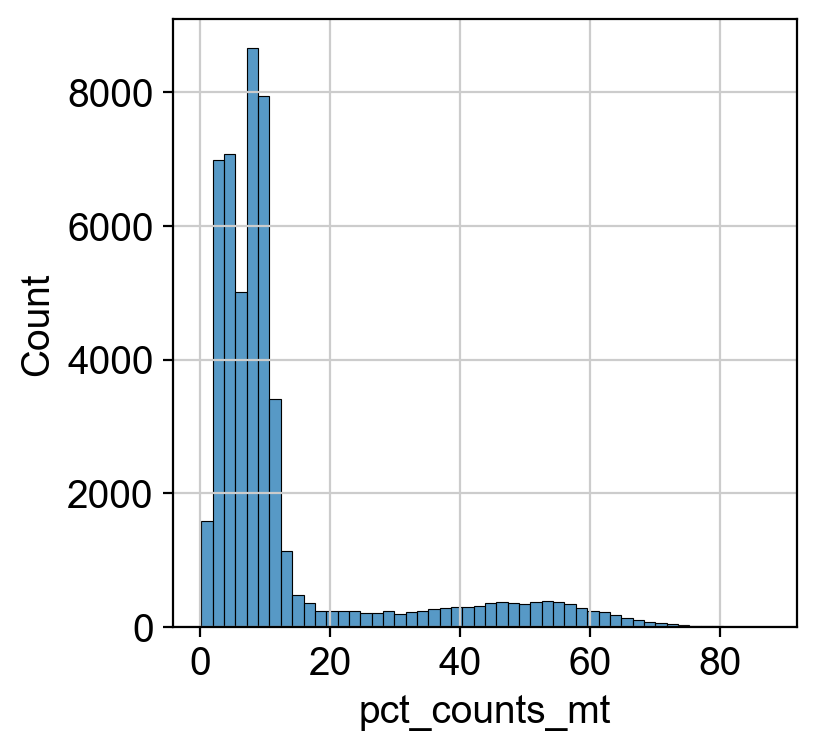

In [27]:
# Look at the QC metric distribution directly
import seaborn as sns
sns.histplot(adata.obs["pct_counts_mt"], bins=50)

#### b. The high proportion of mitochondria in scrna SEQ usually corresponds to low-quality cells. The core reasons include:
Apoptosis / stress: when cells are apoptotic or under stress (such as hypoxia and nutrient deficiency), nuclear membrane rupture leads to degradation of nuclear RNA, while mitochondrial structure is more stable, and mitochondrial RNA is preferentially retained. At this time, "nuclear gene signal is weakened, mitochondrial gene signal is relatively enhanced" in the sequencing data, and the proportion of mitochondria will significantly increase (>10%-15%). The
Dead cells / dying cells: nuclear RNA of dead cells is almost completely degraded, leaving only mitochondrial RNA and a small amount of residual cytosolic RNA. The proportion of mitochondria may exceed 50% or even higher. The
Incomplete cell lysis: in the experimental operation, if the cell lysis is not sufficient and the release of nuclear RNA is insufficient, the proportion of mitochondrial RNA will also passively increase. The
Scrna SEQ (especially 10x genomics technology) relies on the integrity of cells: if dead or apoptotic cells are captured, the RNA fragments after degradation are not the "real transcriptome of living cells" obtained by sequencing. These low-quality data will interfere with subsequent cell clustering and difference analysis (such as the formation of "pseudo cell clusters"), which must be filtered through indicators such as mitochondrial proportion. The

#### c. Draw the "nfeature_rna", "ncount_rna" and "percent.mt" graphs before quality control
(where pct_counts_mt is percent.mt, n_genes_by_counts is nfeature_rna, and total_counts is ncount_rna)

<Figure size 1968.5x393.701 with 0 Axes>

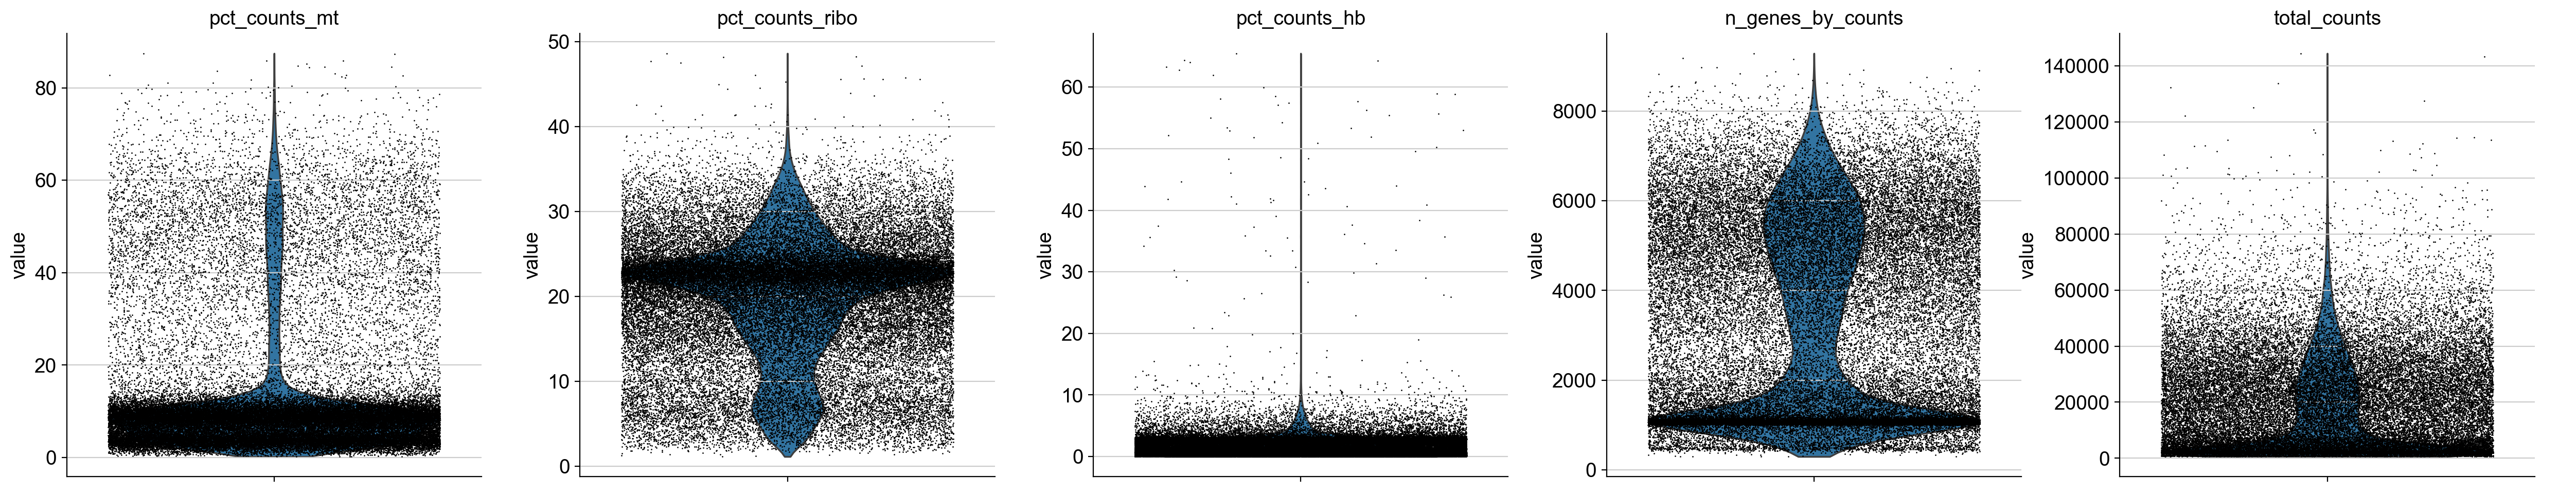

In [28]:
width_cm = 50
height_cm = 10
plt.figure(figsize=(width_cm / 2.54, height_cm / 2.54))
 
sc.pl.violin(
    adata,
    ["pct_counts_mt", "pct_counts_ribo","pct_counts_hb","n_genes_by_counts", "total_counts"],
    jitter=0.4,# horizontal jitter to avoid overlap
    multi_panel=True, # draw each metric in its own panel
    show=False
)
 
plt.savefig("qc_violin_before.pdf",bbox_inches='tight') # saving works without showing (show=False)
plt.show()

==========Cells were filtered according to the paper threshold==========
1. filter the cells with library size <2500 (total_counts is the library size)
2. filter the cells with the proportion of mitochondria >15% (pct_counts_mt is the proportion of mitochondria)

In [29]:
sc.pp.filter_cells(adata, min_counts=2500)  # library size >= 2500
adata = adata[adata.obs['pct_counts_mt'] < 15, :]  # mitochondrial fraction < 15%

#### c. Draw the "nfeature_rna", "ncount_rna" and "percent.mt" diagrams after quality control, and explain their meanings.
A high percentage of mitochondrial genes may indicate cell damage or stress status; The percentage of ribosomal genes reflects the translational activity of the cell; A high percentage of hemoglobin genes may indicate the presence of red blood cell contamination in the sample; The number of detected genes and the total number of UMIS reflect the depth and complexity of cell sequencing. By setting reasonable filtering conditions, low-quality cells and potentially noisy data can be effectively removed, thereby improving the overall quality of single-cell sequencing data. The filtered data are more evenly distributed, reducing the impact of outliers, and providing a more reliable basis for subsequent cell clustering, differential expression analysis and biological function research. The figure shows the distribution of quality control indicators of filtered data, verifies the effectiveness of filtering steps, and ensures the accuracy and reliability of subsequent analysis.

d:\Anaconda\envs\scRNA_new\lib\site-packages\scanpy\plotting\_anndata.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g: sns.axisgrid.FacetGrid = sns.catplot(


<Figure size 1968.5x393.701 with 0 Axes>

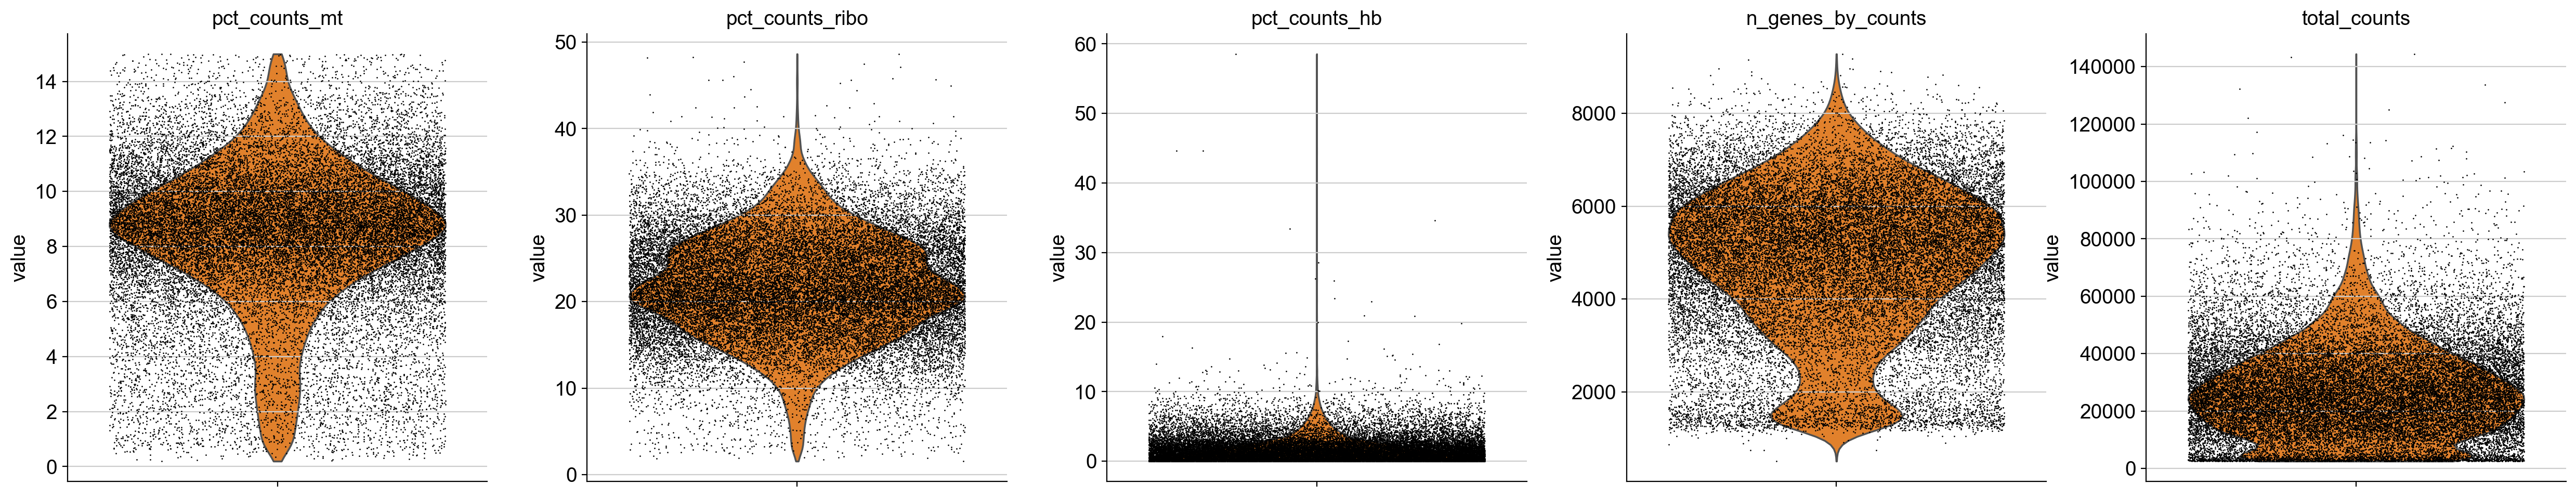

In [30]:
width_cm = 50
height_cm = 10
plt.figure(figsize=(width_cm / 2.54, height_cm / 2.54))
 
sc.pl.violin(
    adata,
    ["pct_counts_mt", "pct_counts_ribo","pct_counts_hb","n_genes_by_counts", "total_counts"],
    jitter=0.4,# horizontal jitter to avoid overlap
    multi_panel=True, # draw each metric in its own panel
    #groupby='sampleid',  # or another group column
    palette=["#ff7f0e"], #["#1f77b4",  "#2ca02c", "#d62728", "#9467bd"],
    show=False
)
 
plt.savefig("qc_violin_after.pdf",bbox_inches='tight') # saving works without showing (show=False)
plt.show()

<Figure size 393.701x393.701 with 0 Axes>

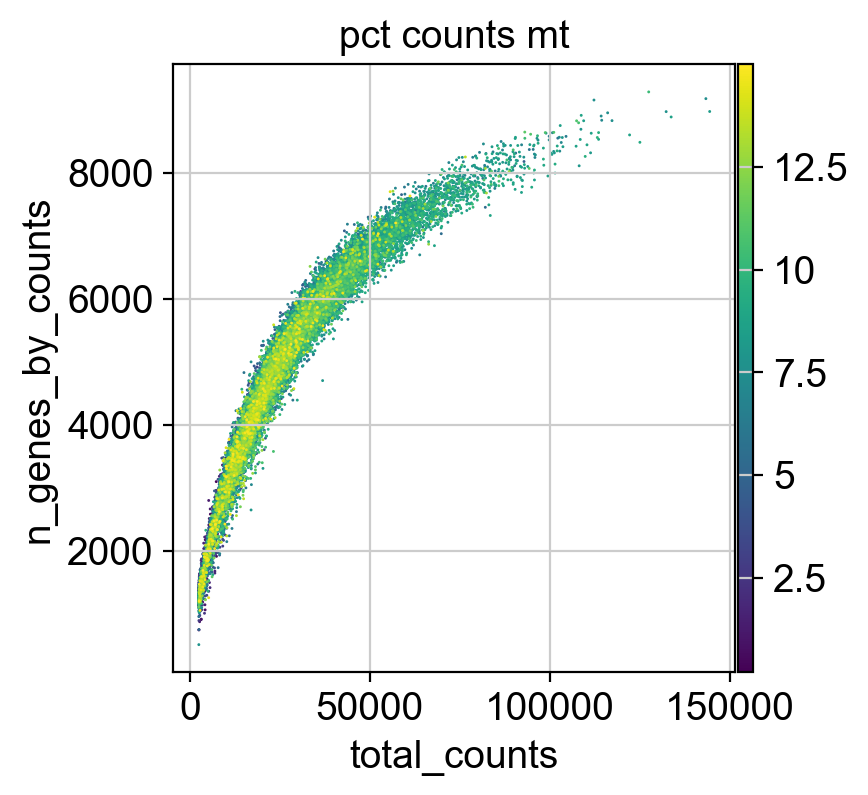

In [31]:
width_cm = 10
height_cm = 10
plt.figure(figsize=(width_cm / 2.54, height_cm / 2.54))
 
sc.pl.scatter(adata, "total_counts", "n_genes_by_counts", color="pct_counts_mt",show=False)
 
plt.savefig("scatterPlot.pdf",bbox_inches='tight') 
plt.show()

The paper mentioned that after filtering, we use the standard workflow implemented in monocle3 to process data. We use python, so we don't use its method

#### a. In single-cell sequencing, some droplets may contain multiple cells, called "double cells", which will lead to inaccurate biological interpretation. A double cell removal algorithm was selected to remove double cells from the data set, and the effect of removing double cells on the results was evaluated.

In [32]:
 # Doublet detection with Scrublet. doublet_score: 0-1, higher = more doublet-like; predicted_doublet: True/False, whether the cell is predicted to be a doublet
sc.pp.scrublet(adata, batch_key="sampleid")

In [33]:
# Keep singlets (non-doublets)
#adata = adata[~adata.obs['predicted_doublet']].copy()
#print(f"Cells remaining after doublet removal: {adata.n_obs}")

In [34]:
# Keep the raw count matrix 
# this step is optional
adata.layers["counts"] = adata.X.copy()
adata.layers


Layers with keys: counts

#### a. Low expression genes were removed, cell quality control, filtering, and expression count normalization.
The following is the standardization of expression technology

In [35]:
# Normalizing to median total counts
sc.pp.normalize_total(adata,target_sum=1e4)
# Logarithmize the data
sc.pp.log1p(adata)

In [36]:
# Keep a copy of the data
adata.raw = adata.copy()

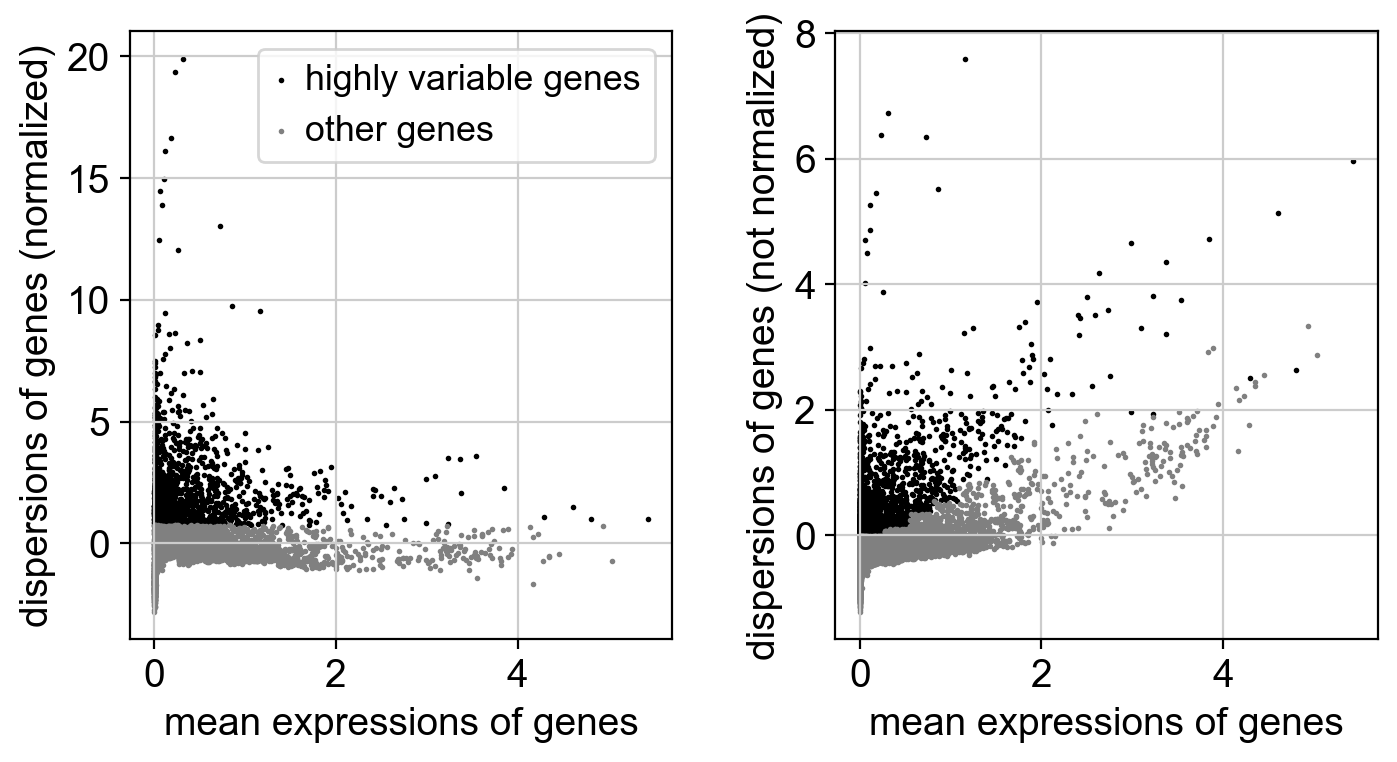

In [37]:
# all genes
#sc.pp.highly_variable_genes(adata, n_top_genes=adata.shape[1], batch_key="sampleid")
#sc.pl.highly_variable_genes(adata)
sc.pp.highly_variable_genes(adata, n_top_genes=2000)  # select highly variable genes first
sc.pl.highly_variable_genes(adata)

In [38]:
# These lists come from the supplementary material of a reference cited by the paper
# G1/S phase genes
g1_s_list = [
    'ACD', 'ACYP1', 'ADAMTS1', 'ANKRD10', 'APEX2', 'ARGLU1', 'ATAD2', 'BARD1', 'BRD7', 'C1orf63', 
    'C7orf41', 'C14orf142', 'CAPN7', 'CASP2', 'CASP8AP2', 'CCNE1', 'CCNE2', 'CDC6', 'CDC25A', 'CDCA7', 
    'CDCA7L', 'CEP57', 'CHAF1A', 'CHAF1B', 'CLSPN', 'CREBZF', 'CTSD', 'DIS3', 'DNAJC3', 'DONSON', 
    'DSCC1', 'DTL', 'E2F1', 'EIF2A', 'ESD', 'FAM105B', 'FAM122A', 'FLAD1', 'GINS2', 'GINS3', 
    'GMNN', 'HELLS', 'HOXB4', 'HRAS', 'HSF2', 'INSR', 'INTS8', 'IVNS1ABP', 'KIAA1147', 'KIAA1586', 
    'LNPEP', 'LUC7L3', 'MCM2', 'MCM4', 'MCM5', 'MCM6', 'MDM1', 'MED31', 'MRI1', 'MSH2', 
    'NASP', 'NEAT1', 'NKTR', 'NPAT', 'NUP43', 'ORC1', 'OSBPL6', 'PANK2', 'PCDH7', 'PCNA', 
    'PLCXD1', 'PMS1', 'PNN', 'POLD3', 'RAB23', 'RECQL4', 'RMI2', 'RNF113A', 'RNPC3', 'SEC62', 
    'SKP2', 'SLBP', 'SLC25A36', 'SNHG10', 'SRSF7', 'SSR3', 'TAF15', 'TIPIN', 'TOPBP1', 'TRA2A', 
    'TTC14', 'UBR7', 'UHRF1', 'UNG', 'USP53', 'VPS72', 'WDR76', 'ZMYND19', 'ZNF367', 'ZRANB2'
]

# S phase genes
s_list = [
    'ABCC5', 'ABHD10', 'ANKRD18A', 'ASF1B', 'ATAD2', 'BBS2', 'BIVM', 'BLM', 'BMI1', 'BRCA1', 
    'BRIP1', 'C5orf42', 'C11orf82', 'CALD1', 'CALM2', 'CASP2', 'CCDC14', 'CCDC84', 'CCDC150', 'CDC7', 
    'CDC45', 'CDCA5', 'CDKN2AIP', 'CENPM', 'CENPQ', 'CERS6', 'CHML', 'COQ9', 'CPNE8', 'CREBZF', 
    'CRLS1', 'DCAF16', 'DEPDC7', 'DHFR', 'DNA2', 'DNAJB4', 'DONSON', 'DSCC1', 'DYNC1LI2', 'E2F8', 
    'EIF4EBP2', 'ENOSF1', 'ESCO2', 'EXO1', 'EZH2', 'FAM178A', 'FANCA', 'FANCI', 'FEN1', 'GCLM', 
    'GOLGA8A', 'GOLGA8B', 'H1F0', 'HELLS', 'HIST1H2AC', 'HIST1H4C', 'INTS7', 'KAT2A', 'KAT2B', 'KDELC1', 
    'KIAA1598', 'LMO4', 'LYRM7', 'MAN1A2', 'MASTL', 'MBD4', 'MCM8', 'MLF1IP', 'MYCBP2', 'NAB1', 
    'NFE2L2', 'NRD1', 'NSUN3', 'NT5DC1', 'NUP160', 'OGT', 'ORC3', 'OSGIN2', 'PHIP', 'PHTF1', 
    'PHTF2', 'PKMYT1', 'POLA1', 'PRIM1', 'PTAR1', 'RAD18', 'RAD51', 'RAD51AP1', 'RBBP8', 'REEP1', 
    'RFC2', 'RHOBTB3', 'RMI1', 'RPA2', 'RRM1', 'RRM2', 'RSRC2', 'SAP30BP', 'SLC38A2', 'SP1', 
    'SRSF5', 'SVIP', 'TOP2A', 'TTC31', 'TTLL7', 'TYMS', 'UBE2T', 'UBL3', 'USP1', 'ZBED5', 'ZWINT'
]

# G2/M phase genes
g2_m_list = [
    'ANLN', 'AP3D1', 'ARHGAP19', 'ARL4A', 'ARMC1', 'ASXL1', 'ATL2', 'AURKB', 'BCLAF1', 'BORA', 
    'BRD8', 'BUB3', 'C2orf69', 'C14orf80', 'CASP3', 'CBX5', 'CCDC107', 'CCNA2', 'CCNF', 'CDC16', 
    'CDC25C', 'CDCA2', 'CDCA3', 'CDCA8', 'CDK1', 'CDKN1B', 'CDKN2C', 'CDR2', 'CENPL', 'CEP350', 
    'CFD', 'CFLAR', 'CHEK2', 'CKAP2', 'CKAP2L', 'CYTH2', 'DCAF7', 'DHX8', 'DNAJB1', 'ENTPD5', 
    'ESPL1', 'FADD', 'FAN1', 'FANCD2', 'G2E3', 'GABPB1', 'GAS1', 'GAS2L3', 'H2AFX', 'HAUS8', 
    'HINT3', 'HIPK2', 'HJURP', 'HMGB2', 'HN1', 'HP1BP3', 'HRSP12', 'IFNAR1', 'IQGAP3', 'KATNA1', 
    'KCTD9', 'KDM4A', 'KIAA1524', 'KIF5B', 'KIF11', 'KIF20B', 'KIF22', 'KIF23', 'KIFC1', 'KLF6', 
    'LBR', 'LIX1L', 'LMNB1', 'MAD2L1', 'MALAT1', 'MELK', 'MGAT2', 'MID1', 'MIS18BP1', 'MND1', 
    'NCAPD3', 'NCAPH', 'NCOA5', 'NDC80', 'NEIL3', 'NFIC', 'NIPBL', 'NMB', 'NR3C1', 'NUCKS1', 
    'NUMA1', 'NUSAP1', 'PIF1', 'PKNOX1', 'POLQ', 'PPP1R2', 'PSMD11', 'PSRC1', 'RANGAP1', 'RCCD1', 
    'RDH11', 'RNF141', 'SAP30', 'SKA3', 'SMC4', 'STAT1', 'STIL', 'STK17B', 'SUCLG2', 'TFAP2A', 
    'TIMP1', 'TMEM99', 'TMPO', 'TNPO2', 'TOP2A', 'TRAIP', 'TRIM59', 'TRMT2A', 'TTF2', 'TUBA1A', 
    'TUBB', 'TUBB2A', 'TUBB4B', 'TUBD1', 'UACA', 'UBE2C', 'VPS25', 'VTA1', 'WSB1', 'ZNF587', 'ZNHIT2'
]

# M phase genes
m_list = [
    'AHI1', 'AKIRIN2', 'ANKRD40', 'ANLN', 'ANP32B', 'ANP32E', 'ARHGAP19', 'ARL6IP1', 'ASXL1', 'ATF7IP', 
    'AURKA', 'BIRC2', 'BIRC5', 'BUB1', 'CADM1', 'CCDC88A', 'CCDC90B', 'CCNA2', 'CCNB2', 'CDC20', 
    'CDC25B', 'CDC27', 'CDC42EP1', 'CDCA3', 'CENPA', 'CENPE', 'CENPF', 'CEP55', 'CFLAR', 'CIT', 
    'CKAP2', 'CKAP5', 'CKS1B', 'CKS2', 'CNOT10', 'CNTROB', 'CTCF', 'CTNNA1', 'CTNND1', 'DEPDC1', 
    'DEPDC1B', 'DIAPH3', 'DNAJA1', 'DNAJB1', 'DR1', 'DZIP3', 'E2F5', 'FAM64A', 'FOXM1', 'FYN', 
    'G2E3', 'GADD45A', 'GAS2L3', 'GOT1', 'GRK6', 'GTSE1', 'HCFC1', 'HMG20B', 'HMGB3', 'HMMR', 
    'HN1', 'HP1BP3', 'HPS4', 'HS2ST1', 'HSPA8', 'HSPA13', 'INADL', 'KIF2C', 'KIF5B', 'KIF14', 
    'KIF20B', 'KLF9', 'LBR', 'LMNA', 'MCM4', 'MDC1', 'MIS18BP1', 'MKI67', 'MLLT4', 'MZT1', 
    'NCAPD2', 'NCOA5', 'NEK2', 'NUF2', 'NUP35', 'NUP98', 'NUSAP1', 'ODF2', 'ORAOV1', 'PBK', 
    'PCF11', 'PLK1', 'POC1A', 'POM121', 'PPP1R10', 'PRPSAP1', 'PRR11', 'PSMG3', 'PTP4A1', 'PTPN9', 
    'PWP1', 'QRICH1', 'RAD51C', 'RANGAP1', 'RBM8A', 'RCAN1', 'RERE', 'RNF126', 'RNF141', 'RNPS1', 
    'RRP1', 'SEPHS1', 'SETD8', 'SFPQ', 'SGOL2', 'SHCBP1', 'SMARCB1', 'SMARCD1', 'SPAG5', 'SPTBN1', 
    'SRF', 'SRSF3', 'SS18', 'SUV420H1', 'TACC3', 'THRAP3', 'TLE3', 'TMEM138', 'TNPO1', 'TOMM34', 
    'TPX2', 'TRIP13', 'TSG101', 'TSN', 'TTK', 'TUBB4B', 'TXNDC9', 'TXNRD1', 'UBE2D3', 'USP13', 
    'USP16', 'VANGL1', 'WIBG', 'WSB1', 'YWHAH', 'ZC3HC1', 'ZFX', 'ZMYM1', 'ZNF207'
]

# M/G1 phase genes
m_g1_list = [
    'AGFG1', 'AGPAT3', 'AKAP13', 'AMD1', 'ANP32E', 'ANTXR1', 'BAG3', 'BTBD3', 'CBX3', 'CDC42', 
    'CDK7', 'CDKN3', 'CEP70', 'CNIH4', 'CTR9', 'CWC15', 'DCP1A', 'DCTN6', 'DEXI', 'DKC1', 
    'DNAJB6', 'DSP', 'DYNLL1', 'EIF4E', 'ELP3', 'FAM60A', 'FAM189B', 'FOPNL', 'FOXK2', 'FXR1', 
    'G3BP1', 'GATA2', 'GNB1', 'GRPEL1', 'GSPT1', 'GTF3C4', 'HIF1A', 'HMG20B', 'HMGCR', 'HSD17B11', 
    'HSPA8', 'ILF2', 'JMJD1C', 'KDM5B', 'KIAA0586', 'KIF5B', 'KPNB1', 'KRAS', 'LARP1', 'LARP7', 
    'LRIF1', 'LYAR', 'MORF4L2', 'MRPL19', 'MRPS2', 'MRPS18B', 'MSL1', 'MTPN', 'NCOA3', 'NFIA', 
    'NFIC', 'NUCKS1', 'NUFIP2', 'NUP37', 'ODF2', 'OPN3', 'PAK1IP1', 'PCF11', 'PLIN3', 'PPP2CA', 
    'PPP2R2A', 'PPP6R3', 'PRC1', 'PSEN1', 'PTMS', 'PTTG1', 'RAD21', 'RAN', 'RHEB', 'RPL13A', 
    'SLC39A10', 'SNUPN', 'SRSF3', 'STAG1', 'SYNCRIP', 'TAF9', 'TCERG1', 'TLE3', 'TMEM138', 'TOB2', 
    'TOP1', 'TROAP', 'TSC22D1', 'TULP4', 'UBE2D3', 'VANGL1', 'VCL', 'WIPF2', 'WWC1', 'YY1', 
    'ZBTB7A', 'ZCCHC10', 'ZNF24', 'ZNF281', 'ZNF593'
]

In [39]:
# Filter: keep genes present in adata (important, avoids failed matches)
gene_sets = {
    'G1S_score': [g for g in g1_s_list if g in adata.var_names],
    'S_score': [g for g in s_list if g in adata.var_names],
    'G2M_score': [g for g in g2_m_list if g in adata.var_names],
    'M_score': [g for g in m_list if g in adata.var_names],
    'MG1_score': [g for g in m_g1_list if g in adata.var_names]
}

# Print the number of genes kept (check the matching)
for name, genes in gene_sets.items():
    print(f"{name}: {len(genes)} genes matched")

# Keep sc.tl.score_genes_cell_cycle (S + G2M, automatic phase assignment)
sc.tl.score_genes_cell_cycle(adata, s_genes=gene_sets['S_score'], g2m_genes=gene_sets['G2M_score'])

# Also score G1/S, M and M/G1 (use all five lists)
sc.tl.score_genes(adata, gene_list=gene_sets['G1S_score'], score_name='G1S_score')
sc.tl.score_genes(adata, gene_list=gene_sets['M_score'], score_name='M_score')
sc.tl.score_genes(adata, gene_list=gene_sets['MG1_score'], score_name='MG1_score')

# 5. Check the result: adata.obs now has all five scores + the assigned phase
print(adata.obs[['G1S_score', 'S_score', 'G2M_score', 'M_score', 'MG1_score', 'phase']].head())



G1S_score: 96 genes matched
S_score: 110 genes matched
G2M_score: 131 genes matched
M_score: 147 genes matched
MG1_score: 103 genes matched
                      G1S_score   S_score  G2M_score   M_score  MG1_score  \
AAACCCAAGAAACACT-1_0   0.183641  0.118312   0.128030  0.107504   0.228284   
AAACCCAAGCAGGGAG-1_0   0.190100  0.159301   0.132928  0.143580   0.245955   
AAACCCAAGGCTCTAT-1_0   0.223594  0.121011   0.086690  0.143597   0.279506   
AAACCCAAGTCGCCCA-1_0   0.060940  0.048077   0.077874  0.183930   0.284185   
AAACCCACACAACGTT-1_0   0.103929  0.055372   0.151762  0.292079   0.392081   

                     phase  
AAACCCAAGAAACACT-1_0   G2M  
AAACCCAAGCAGGGAG-1_0     S  
AAACCCAAGGCTCTAT-1_0     S  
AAACCCAAGTCGCCCA-1_0   G2M  
AAACCCACACAACGTT-1_0   G2M  


In [40]:
cell_cycle_genes = g1_s_list + s_list + g2_m_list + m_list + m_g1_list
cell_cycle_genes = [g for g in cell_cycle_genes if g in adata.var_names]
adata_cc_genes = adata[:, cell_cycle_genes]
sc.pp.scale(adata_cc_genes, zero_center=True, max_value=10)
sc.tl.pca(adata_cc_genes, n_comps=50, use_highly_variable=False, svd_solver='arpack')

d:\Anaconda\envs\scRNA_new\lib\site-packages\scanpy\preprocessing\_scale.py:318: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)
d:\Anaconda\envs\scRNA_new\lib\site-packages\anndata\_core\anndata.py:1756: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
d:\Anaconda\envs\scRNA_new\lib\site-packages\scanpy\preprocessing\_pca.py:377: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  warn(msg, FutureWarning)


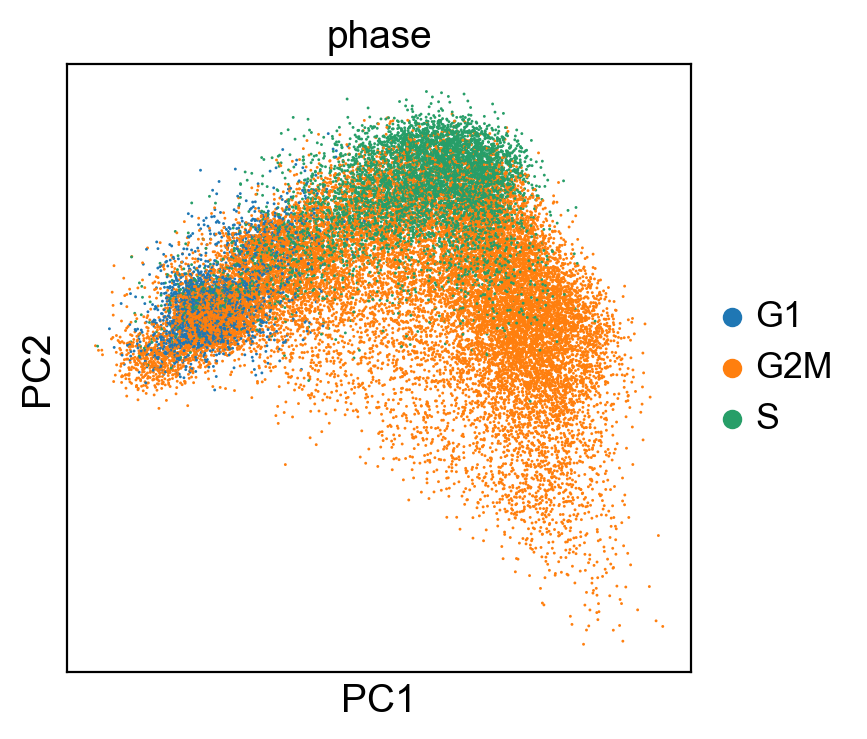

In [41]:
sc.pl.pca_scatter(adata_cc_genes, color='phase')

In [42]:
sc.pp.regress_out(adata, ['G1S_score', 'S_score', 'G2M_score', 'M_score', 'MG1_score'])

d:\Anaconda\envs\scRNA_new\lib\site-packages\scanpy\preprocessing\_scale.py:318: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)
d:\Anaconda\envs\scRNA_new\lib\site-packages\anndata\_core\anndata.py:1756: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


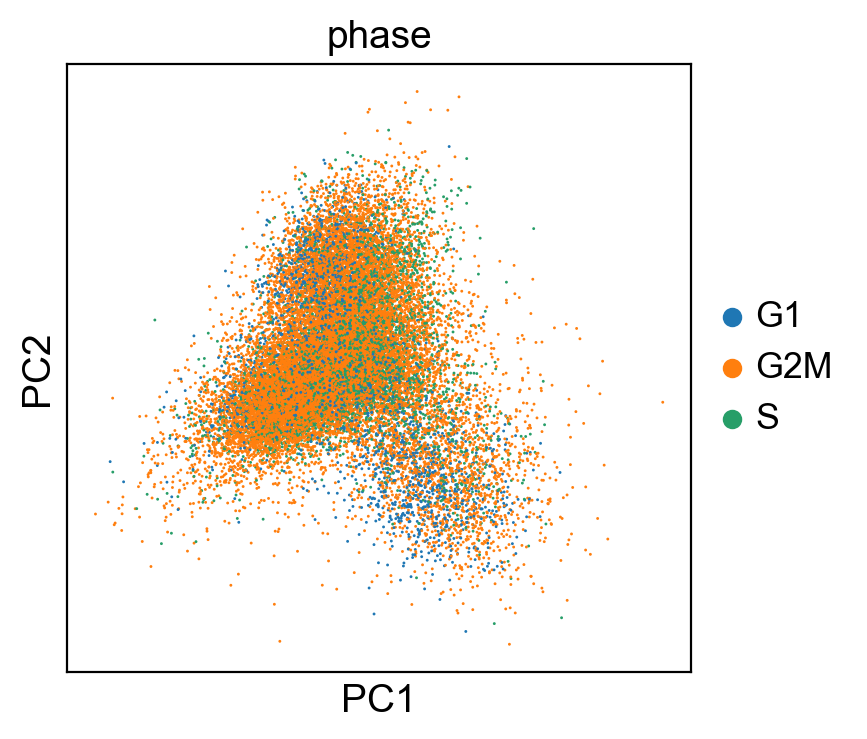

In [43]:
adata_cc_genes = adata[:, cell_cycle_genes]
sc.pp.scale(adata_cc_genes, max_value=10) # max_value can also be None
sc.tl.pca(adata_cc_genes)
sc.pl.pca_scatter(adata_cc_genes, color='phase')

In [44]:
# Scale the whole dataset
sc.pp.scale(adata, max_value=10)
# PCA
sc.tl.pca(adata,n_comps=50,use_highly_variable=True)
# regress the cell-cycle effect during PCA (without changing the raw expression matrix)


d:\Anaconda\envs\scRNA_new\lib\site-packages\scanpy\preprocessing\_pca.py:377: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  warn(msg, FutureWarning)


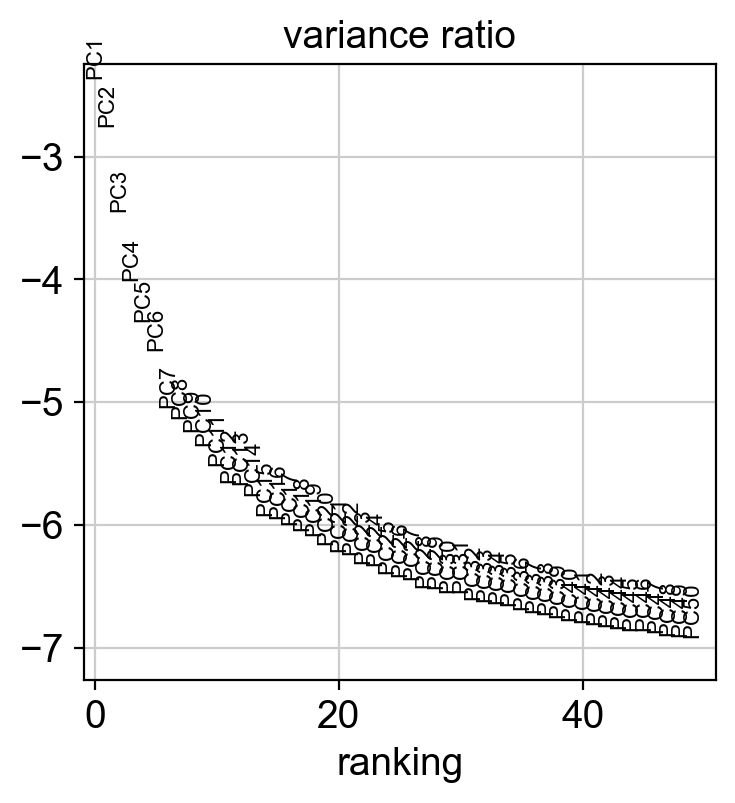

In [45]:
# use this plot to choose the number of PCs
sc.pl.pca_variance_ratio(adata,n_pcs=50,log=True)

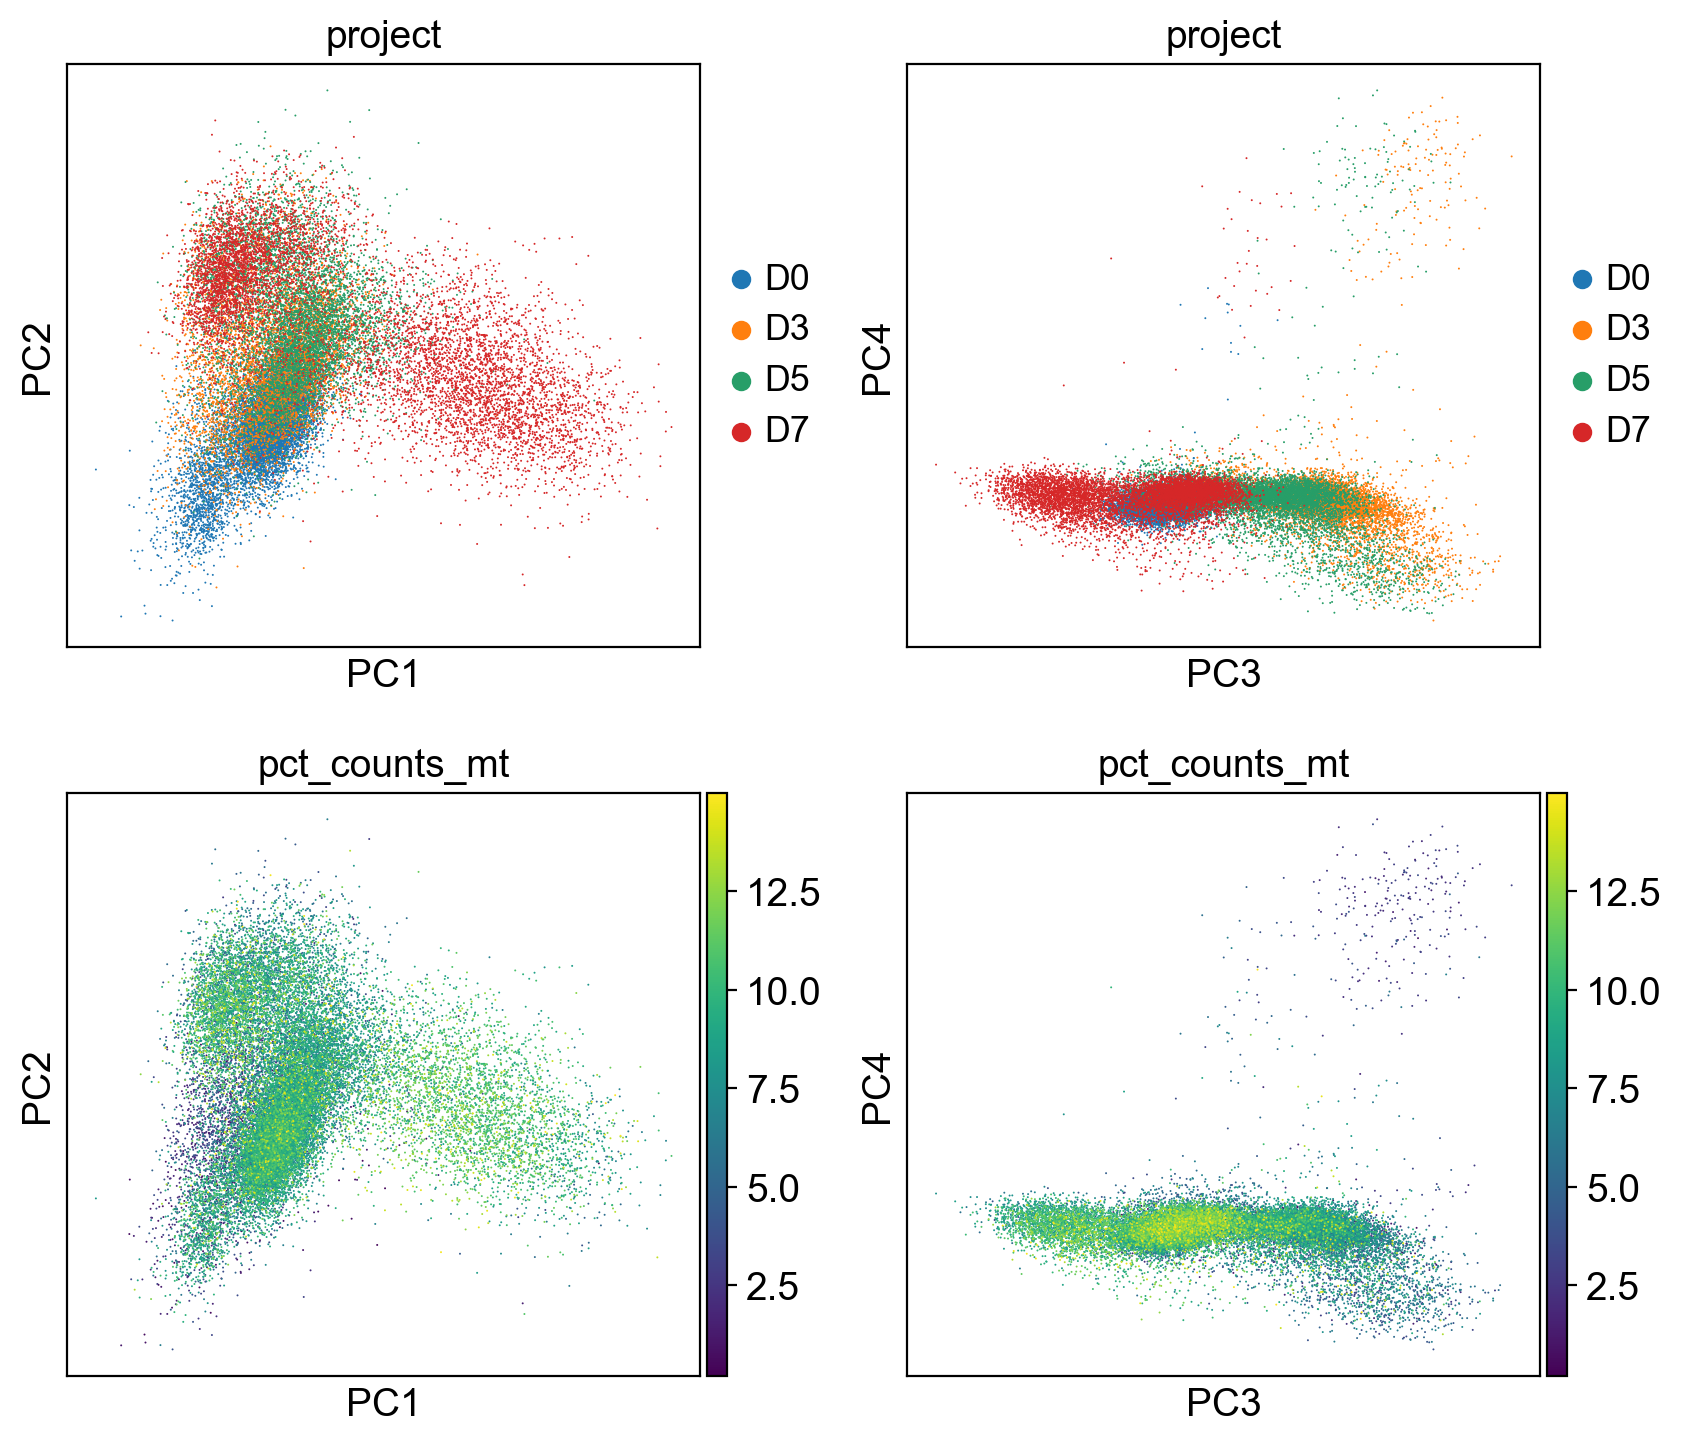

In [46]:

# Check the PCA by different groupings
sc.pl.pca(
    adata,
    color = ["project","project","pct_counts_mt","pct_counts_mt"],# what to color by
    dimensions=[(0,1),(2,3),(0,1),(2,3)], # which PCs to show
    ncols =2,
    size =2,
    
)

# 2. eliminate batch effect 
#### b. draw the umap/t-sne visualization map before removing batch effects, refer to figure 5A in the original study


d:\Anaconda\envs\scRNA_new\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
d:\Anaconda\envs\scRNA_new\lib\site-packages\umap\__init__.py:36: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


<Figure size 393.701x393.701 with 0 Axes>

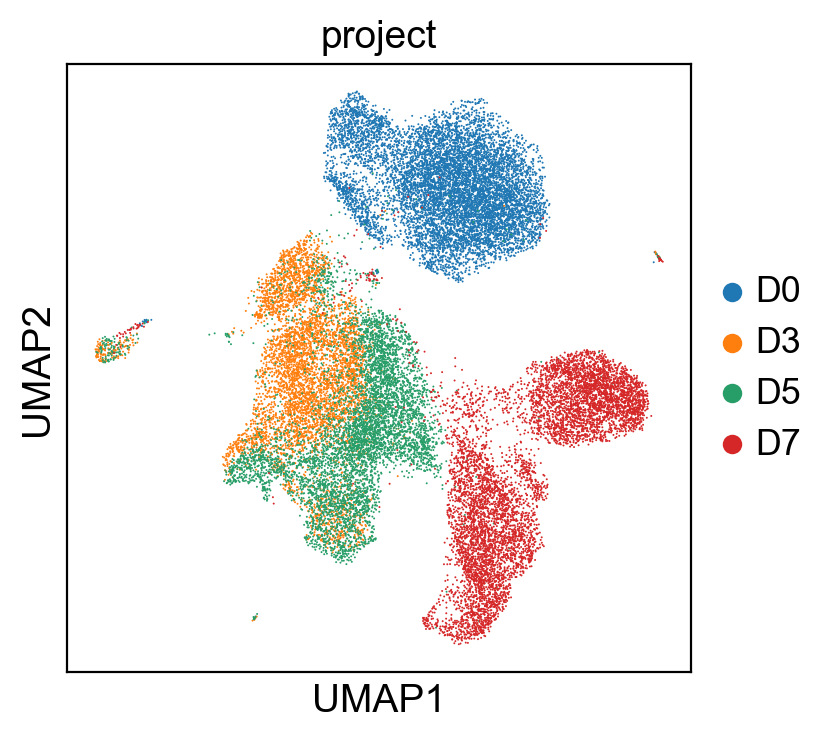

In [47]:
sc.pp.neighbors(adata, n_neighbors=10, n_pcs=50)# 50 PCs as given in the paper
# UMAP
sc.tl.umap(adata)
width_cm = 10
height_cm = 10
plt.figure(figsize=(width_cm / 2.54, height_cm / 2.54))
 
sc.pl.umap(
    adata,
    color="project",
    # Setting a smaller point size to get prevent overlap
    size=2,
    show=False
)
 
plt.savefig("umap_non.pdf",bbox_inches='tight') # saving works without showing (show=False)
plt.show()

#### a.The paper uses the mutual nearest neighbor comparison method (haghverdi et al., 2018) to remove batch effects, but this method is based on R language
We used bbknn to eliminate batches
The k-nearest neighbor logic of batch balance: bbknn allows each cell to find neighbors independently in each batch and then merge, avoiding the "over integration" caused by global neighbor finding, and preserving the biological differences of cell types / differentiation stages (adapting to your analysis needs of samples at four differentiation time points); The
Light weight and high efficiency: it does not need to modify the expression matrix, directly optimizes the construction of nearest neighbor graph, has fast calculation and good adaptability to medium-sized datasets (such as thousands of cells per sample); The
Avoid fuzzy grouping: compared with the problem that harmony is easy to "wipe out" cell subpopulations, bbknn can effectively eliminate batch effects, maintain a clear cell cluster structure, and solve the problem of umap sticking together before. 

In [48]:
adata_bb=adata.copy()

In [49]:
import scanpy.external as sce 
# Run BBKNN (main parameters tuned)
sce.pp.bbknn(
    adata_bb,
    batch_key='project',  
    neighbors_within_batch=5,  # only 5 neighbors per batch (5 x 4 = 20 in total, fewer cross-cluster edges)
    n_pcs=50,  # as suggested by the paper
    trim=20,  # strict neighbor trimming (keep only the strongest edges)
    approx=True,
    metric='cosine'  # cosine distance (separates cell types better than Euclidean)
)

#### b. Draw the visualization map of umap/t-sne after removing batch effects, refer to 5B in the original study.

<Figure size 393.701x393.701 with 0 Axes>

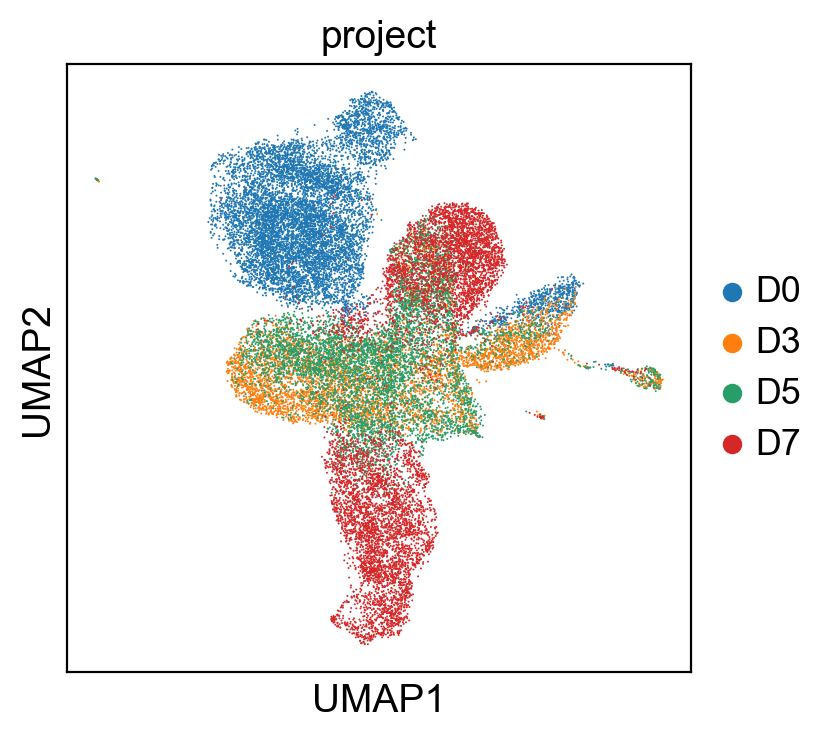

In [50]:
# Then we calculate a new umap and tsne.
#sc.pp.neighbors(adata, n_neighbors=15, n_pcs=50, use_rep='X_pca_harmony')
#sc.tl.umap(adata)
sc.tl.umap(
    adata_bb,
    min_dist=0.5,  # increase the distance between clusters
    spread=1.2,    # spread the clusters more
    random_state=42,
)
# sc.tl.tsne(adata, use_rep='X_pca_harmony')
# sc.tl.leiden(adata, resolution=0.5)
width_cm = 10
height_cm = 10
plt.figure(figsize=(width_cm / 2.54, height_cm / 2.54))
 
sc.pl.umap(
    adata_bb,
    color="project",
    # Setting a smaller point size to get prevent overlap
    size=2,
    show=False
)
 
plt.savefig("umap_scanorama.pdf",bbox_inches='tight') 
plt.show()

In [51]:
# 3. Clustering (Leiden, tuned resolution)
sc.tl.leiden(
    adata_bb, 
    resolution=0.5,  # moderate resolution (the paper's 1.5e-5 may be too small and merge clusters)
    random_state=42
)

C:\Users\<user>\AppData\Local\Temp\ipykernel_23460\2147964637.py:2: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(


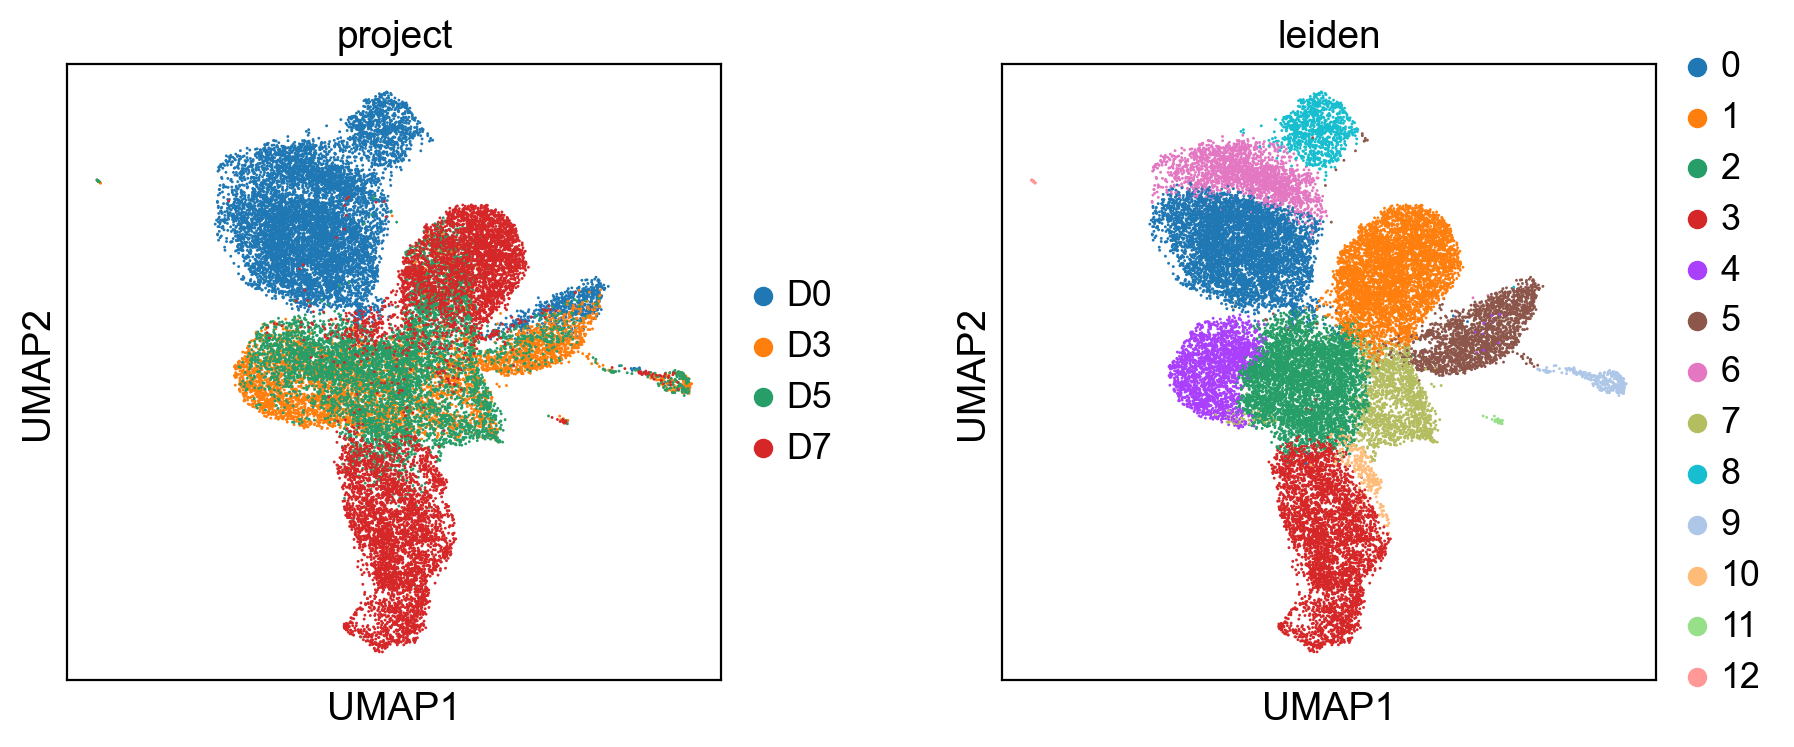

In [52]:
sc.pl.umap(
    adata_bb, 
    color=['project', 'leiden'],  # batch + clusters
    ncols=2,  # two columns
    wspace=0.3,  # spacing
)

In [53]:
#del adata  # delete the old adata variable
adata=adata_bb


# Cell clustering and annotation 
#### a. perform cell clustering and annotation, refer to figure 5B in the original literature. The marker genes used for annotation are taken from figure 5e-g.

In [54]:
marker_genes = {
    "EB (Erythroblast)": ["GYPA", "KLF1", "EPB42"],  # C1/C2, erythroid markers from Figure 5E
    "EB_like": ["ITGA2B", "IFI27", "HBD"],  # C2, additional erythroid markers from Figure 5D and the paper text
    "iPEM": ["CD44", "LMO4", "ANXA1"],  # C3, markers from Figure 5F
    "iMK": ['ITGA6','GP1BA','GP9','F2R'], #,'SELP'],  # C4/C5, megakaryocyte markers from Figures 5G and 5D
    "iMK_2": ['CD53','CD52','KIT']  # C5, additional megakaryocyte markers from Figure 5I and the paper text
}

In [55]:
# Check that the genes are in adata.var_names
all_genes = adata.var_names.tolist()
marker_genes_check = {
    cell_type: [gene for gene in genes if gene in all_genes] 
    for cell_type, genes in marker_genes.items()
}
# Print missing genes
for cell_type, genes in marker_genes.items():
    missing = [gene for gene in genes if gene not in all_genes]
    if missing:
        print(f"Missing genes for cell type {cell_type}: {missing}")

<Figure size 1181.1x393.701 with 0 Axes>

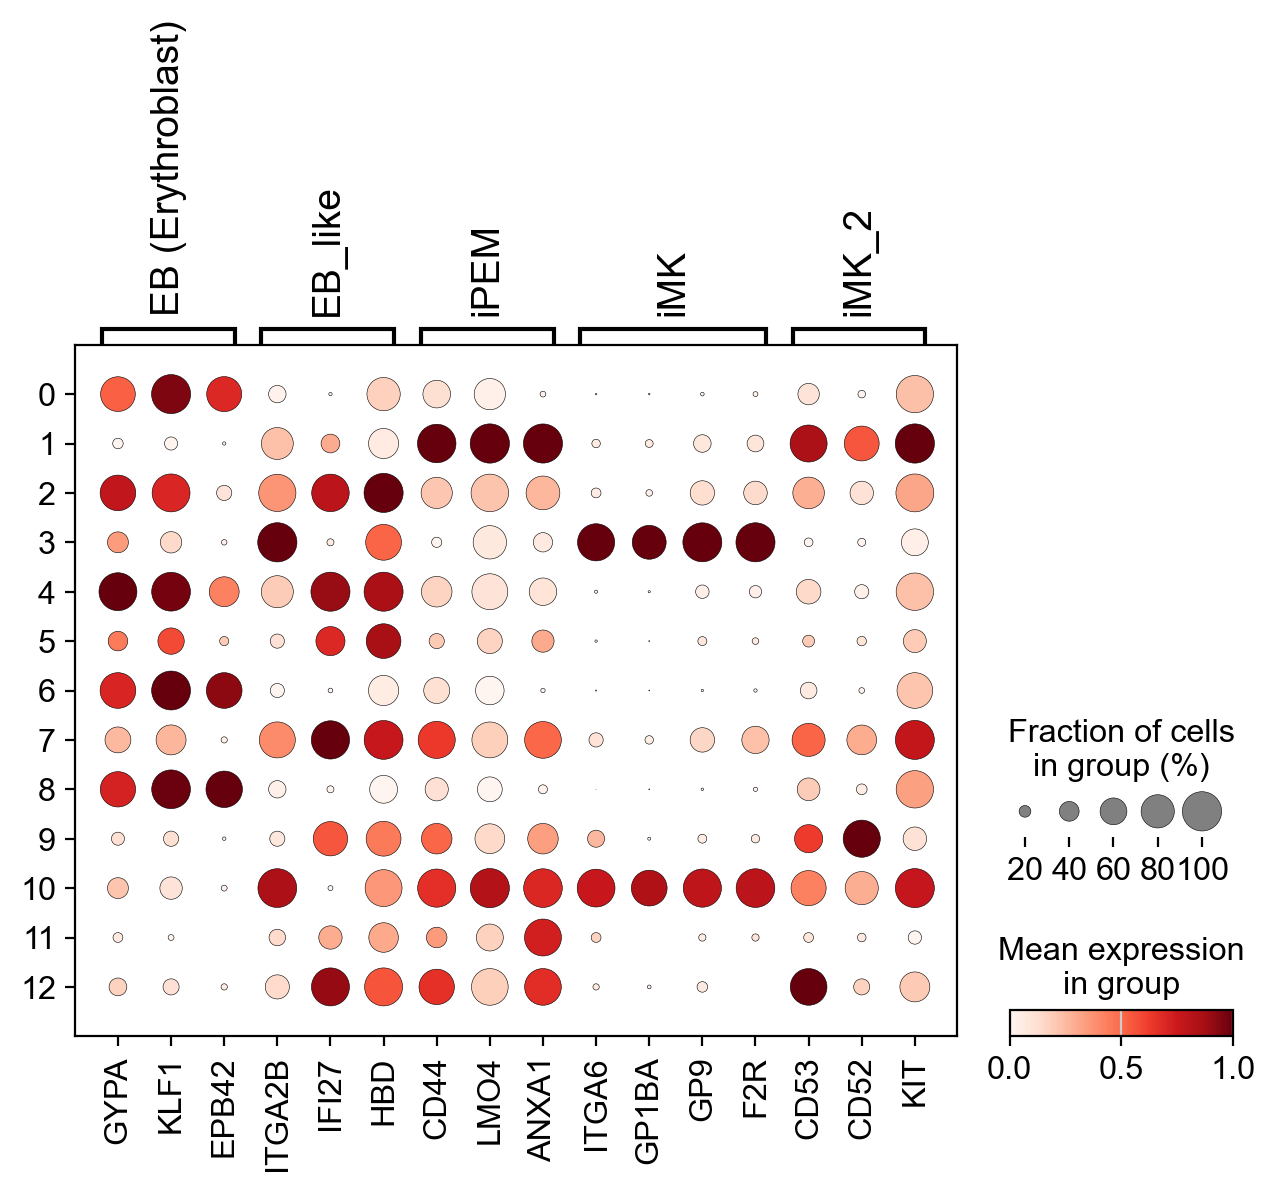

In [56]:
width_cm = 30
height_cm = 10
plt.figure(figsize=(width_cm / 2.54, height_cm / 2.54))
 
sc.pl.dotplot(adata, 
              marker_genes,
              groupby="leiden", 
              standard_scale="var",
             show =False
             )
 
plt.savefig("leiden_marker.pdf",bbox_inches='tight')
plt.show()

In [57]:
# Get all cluster IDs, sorted, as strings (for matching later)
cluster_ids = sorted(adata.obs['leiden'].unique().tolist())
cluster_ids = [str(c) for c in cluster_ids]  # convert to strings
 
# Initialize the DataFrame with every celltype set to 'Unknown'
celltype = pd.DataFrame({
    'ClusterID': cluster_ids,
    'celltype': ['Unknown'] * len(cluster_ids)
})
 
celltype

,ClusterID,celltype
0,0,Unknown
1,1,Unknown
2,10,Unknown
3,11,Unknown
4,12,Unknown
5,2,Unknown
6,3,Unknown
7,4,Unknown
8,5,Unknown
9,6,Unknown


In [58]:
# Erythroid precursors / erythroid cells
celltype.loc[celltype['ClusterID'].isin(['0', '6', '8','']), 'celltype'] = 'EB (Erythroblast)'
celltype.loc[celltype['ClusterID'].isin(['2', '7','4','5']), 'celltype'] = 'EB-like cells'

# Precursors
celltype.loc[celltype['ClusterID'].isin(['1', '', '9','11','12','']), 'celltype'] = 'iPEM cells'

# Megakaryocyte lineage
celltype.loc[celltype['ClusterID'].isin(['3', ' ']), 'celltype'] = 'iMK_1 cells'
celltype.loc[celltype['ClusterID'].isin(['10']), 'celltype'] = 'iMK_2 cells'



In [59]:
# Map the celltype information back to adata.obs
# Make sure the cluster column in adata.obs is a string
adata.obs['leiden_str'] = adata.obs['leiden'].astype(str)
 
# Mapping dictionary: cluster_id -> celltype
mapping = dict(zip(celltype['ClusterID'], celltype['celltype']))
 
# Add the celltype of each cell with the mapping (new celltype column)
adata.obs['celltype'] = adata.obs['leiden_str'].map(mapping)
 
# Check the distribution
print(adata.obs['celltype'].value_counts())

EB-like cells        10340
EB (Erythroblast)     8365
iPEM cells            5376
iMK_1 cells           3764
iMK_2 cells            237
Name: celltype, dtype: int64


#### b. Create t-sne/umap maps with cell type annotations, as shown in Figure 5B.

<Figure size 393.701x393.701 with 0 Axes>

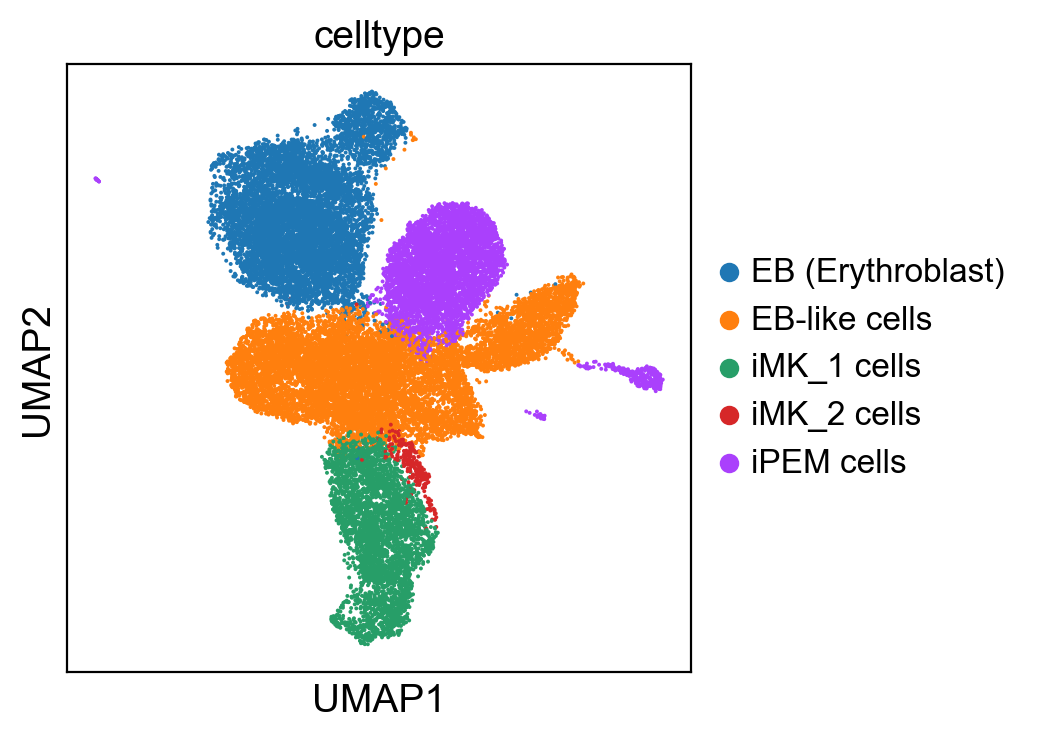

In [60]:
width_cm = 10
height_cm = 10
plt.figure(figsize=(width_cm / 2.54, height_cm / 2.54))
fig = sc.pl.umap(
    adata,
    color=["celltype"],
    #legend_loc="on data",
    frameon=True,
    size=8,            # point size, change as needed
    legend_fontsize=12, # legend font size
    show=False)
 
# Loop over all text objects and set the font size
for txt in fig.axes.texts:
    txt.set_fontsize(7)  # font size you want
 
 
plt.savefig("celltype.pdf",bbox_inches='tight') 
plt.show()

#### c. Referring to Figures 5d and 5h, draw a heatmap and violin plots of the within-cluster marker-gene expression.

<Figure size 1181.1x393.701 with 0 Axes>

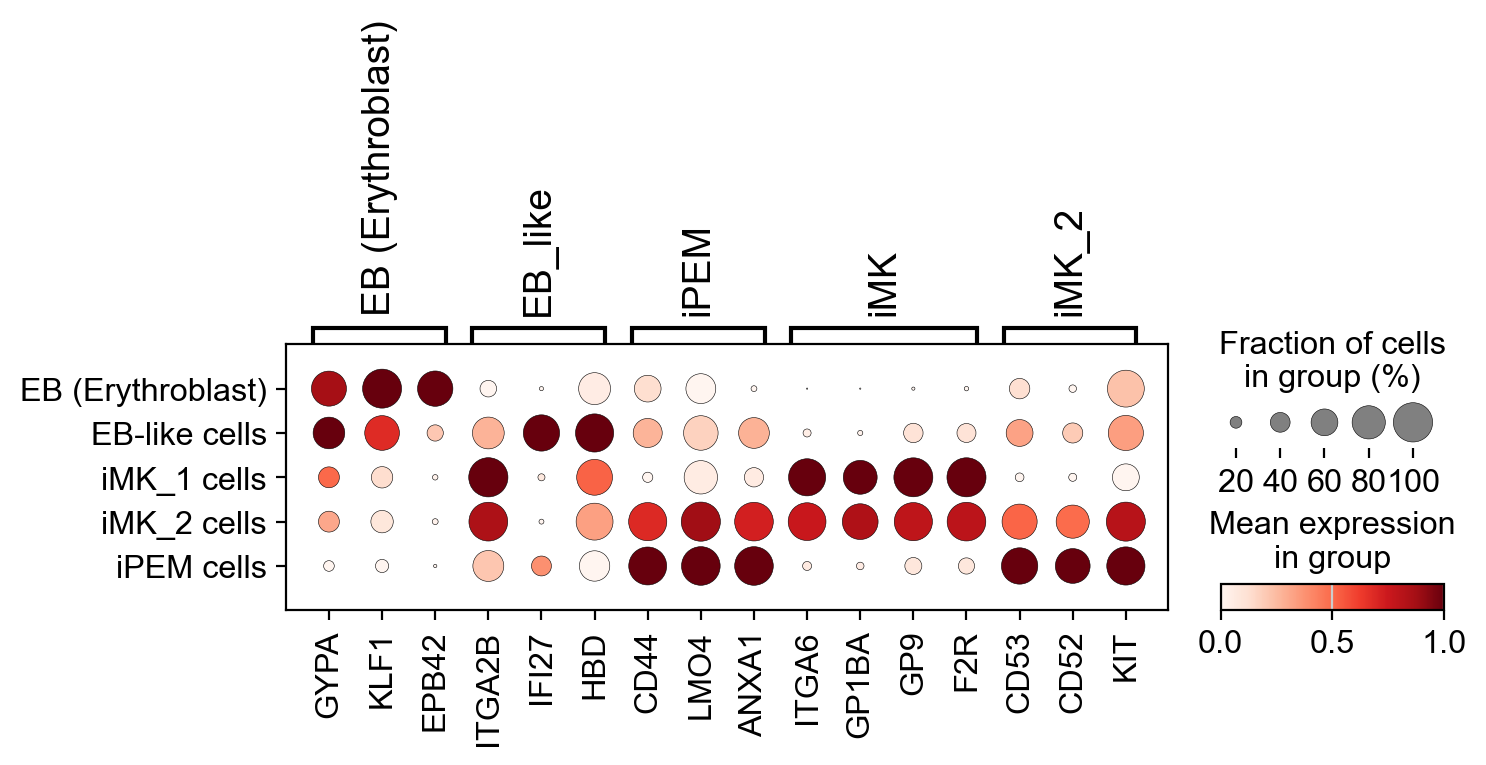

In [61]:
width_cm = 30
height_cm = 10
plt.figure(figsize=(width_cm / 2.54, height_cm / 2.54))
 
sc.pl.dotplot(adata, 
              marker_genes,
              groupby="celltype", 
              standard_scale="var",
             show =False
             )
 
plt.savefig("celltype_marker.pdf",bbox_inches='tight')
plt.show()

<Figure size 1181.1x393.701 with 0 Axes>

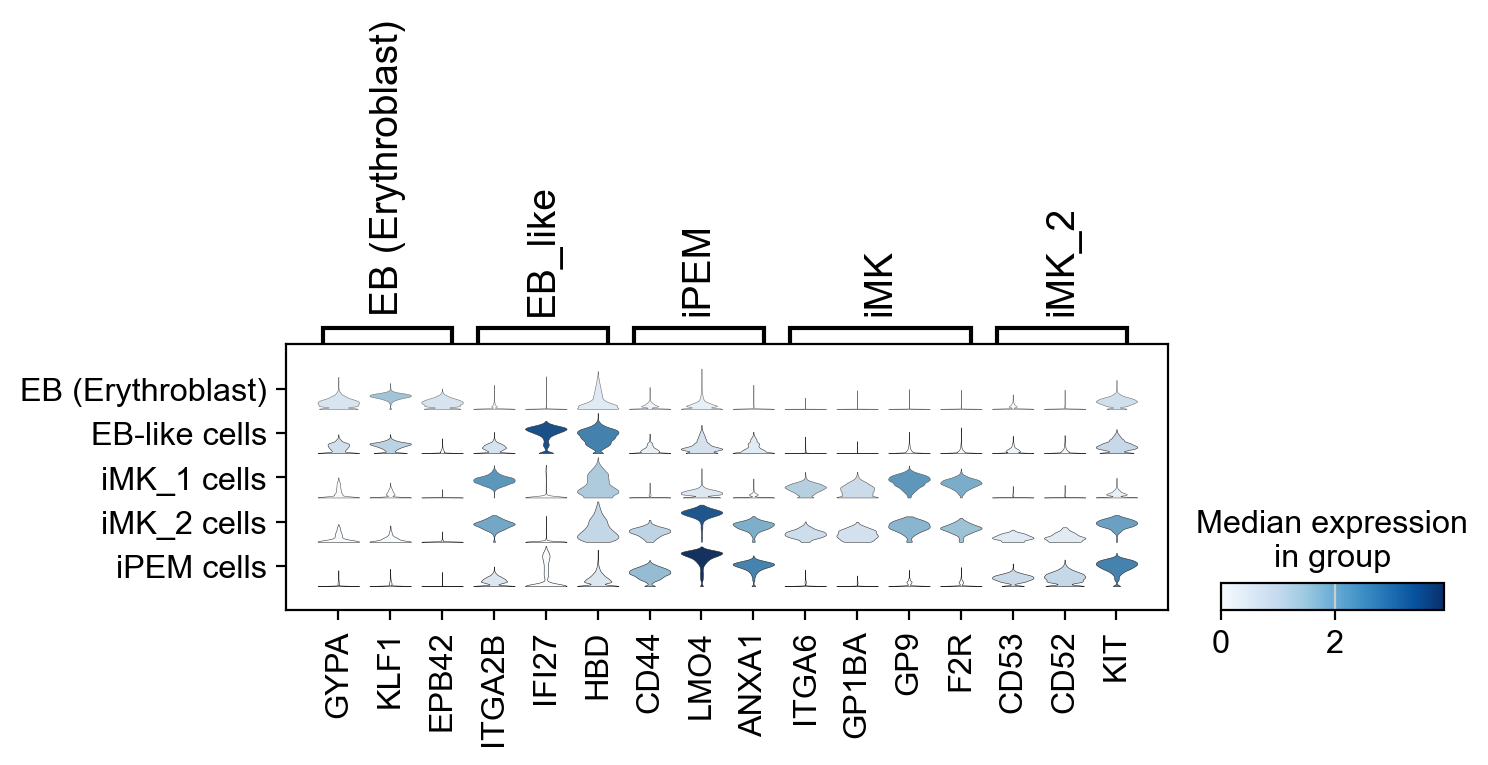

<Figure size 400x400 with 0 Axes>

In [62]:
width_cm = 30
height_cm = 10
plt.figure(figsize=(width_cm / 2.54, height_cm / 2.54))
 
sc.pl.stacked_violin(adata, 
                     marker_genes,
                     groupby="celltype")
 
plt.savefig("celltype_marker2.pdf",bbox_inches='tight',dpi=300)
plt.show()

#### d. As shown in Figure 5c, visualize the sample proportions for each cell-type cluster.

In [63]:
import seaborn as sns

In [64]:
# 1. Count cells per cell type and sample
counts = adata.obs.groupby(['celltype', 'project']).size().reset_index(name='count')

# 2. Fraction of each cell type coming from each sample
celltype_totals = counts.groupby('celltype')['count'].sum()  # total cells per cell type
counts['proportion'] = counts.apply(lambda x: x['count'] / celltype_totals[x['celltype']], axis=1)

# 3. Pivot table (for plotting)
proportion_pivot = counts.pivot(index='celltype', columns='project', values='proportion').fillna(0)

In [65]:
cell_order = ["EB (Erythroblast)", "EB-like cells", "iPEM cells", "iMK_1 cells", "iMK_2 cells"]
proportion_pivot = proportion_pivot.reindex(cell_order)  # reorder rows

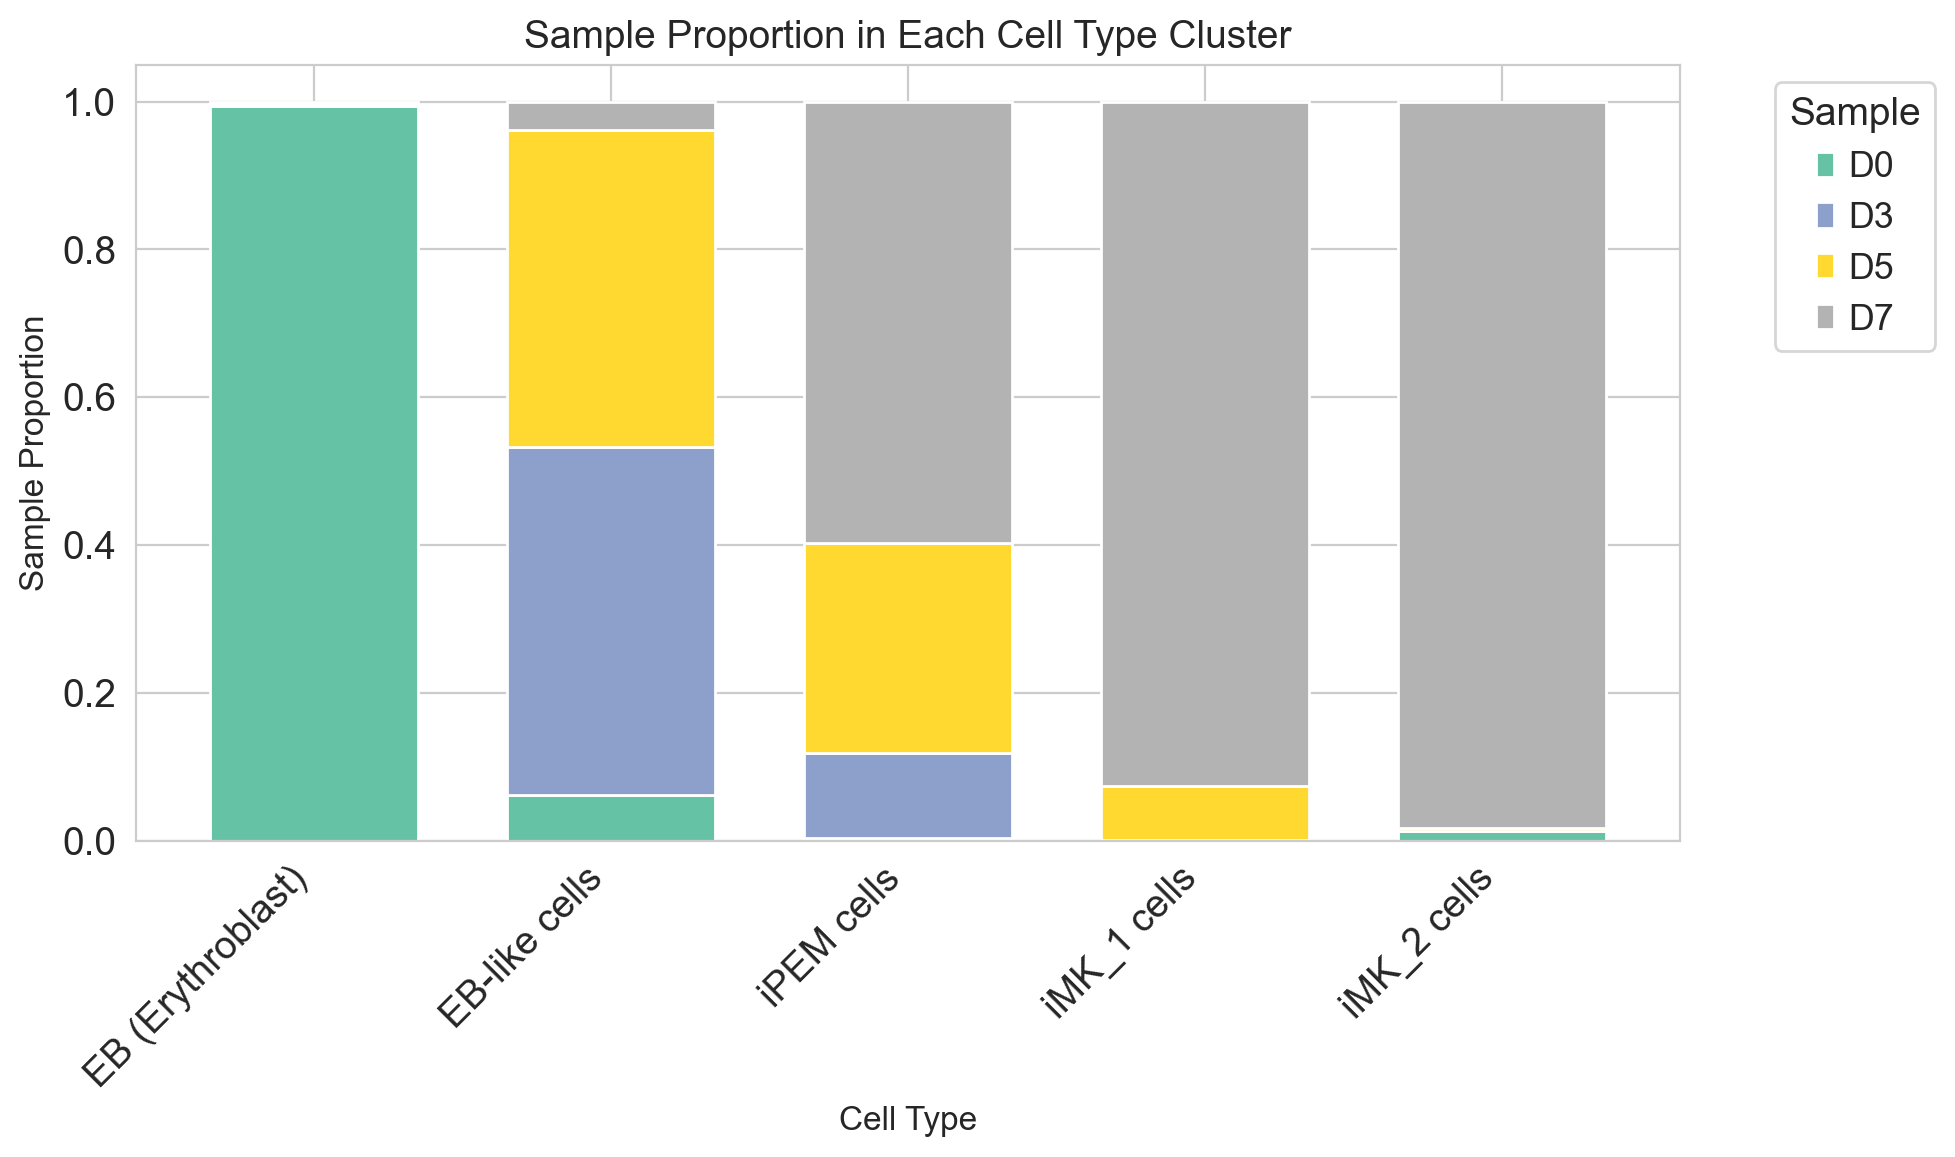

In [66]:
# Plot style
plt.figure(figsize=(10, 6))
sns.set_style('whitegrid')

# Stacked bar chart
proportion_pivot.plot(
    kind='bar', 
    stacked=True, 
    ax=plt.gca(),
    colormap='Set2',  # color scheme, e.g. 'viridis' or 'tab10'
    width=0.7  # bar width
)

# Labels and title
plt.xlabel('Cell Type', fontsize=12)
plt.ylabel('Sample Proportion', fontsize=12)
plt.title('Sample Proportion in Each Cell Type Cluster', fontsize=14)
plt.xticks(rotation=45, ha='right')  # rotate x labels to avoid overlap
plt.legend(title='Sample', bbox_to_anchor=(1.05, 1), loc='upper left')  # legend on the right

# Adjust the layout and save
plt.tight_layout()
plt.savefig('celltype_sample_proportion.pdf', dpi=300)
plt.show()

# GO Enrichment Analysis of Cell-Cluster Marker Genes

#### a. Select two cell clusters and perform GO enrichment analysis, referring to Figure 5j.

#### b. Present and interpret the GO enrichment results.

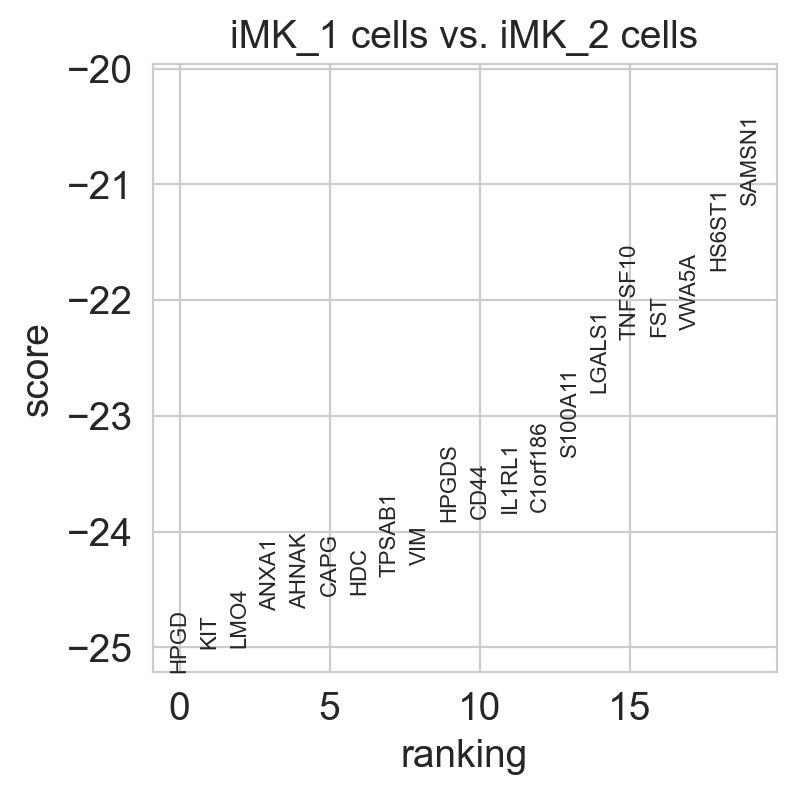

In [67]:
sc.tl.rank_genes_groups(
    adata, 
    groupby="celltype",       # group by cell type
    groups=["iMK_1 cells"],         # cluster to test (iMK-1)
    reference="iMK_2 cells",        # reference group (iMK-2)
    method="wilcoxon",        # common single-cell DE method (t-test, logreg etc. also possible)
    rankby_abs=True           # rank by absolute score (optional)
)

# DE results (genes up in iMK-1 vs iMK-2)
sc.pl.rank_genes_groups(adata, groups=["iMK_1 cells"], n_genes=20, sharey=False)

# Extract DE genes (up in iMK-1)
imk1_markers = sc.get.rank_genes_groups_df(adata, group="iMK_1 cells", log2fc_min=0.5, pval_cutoff=0.05)

In [68]:
# GO/KEGG enrichment with gseapy
import  gseapy  as  gp

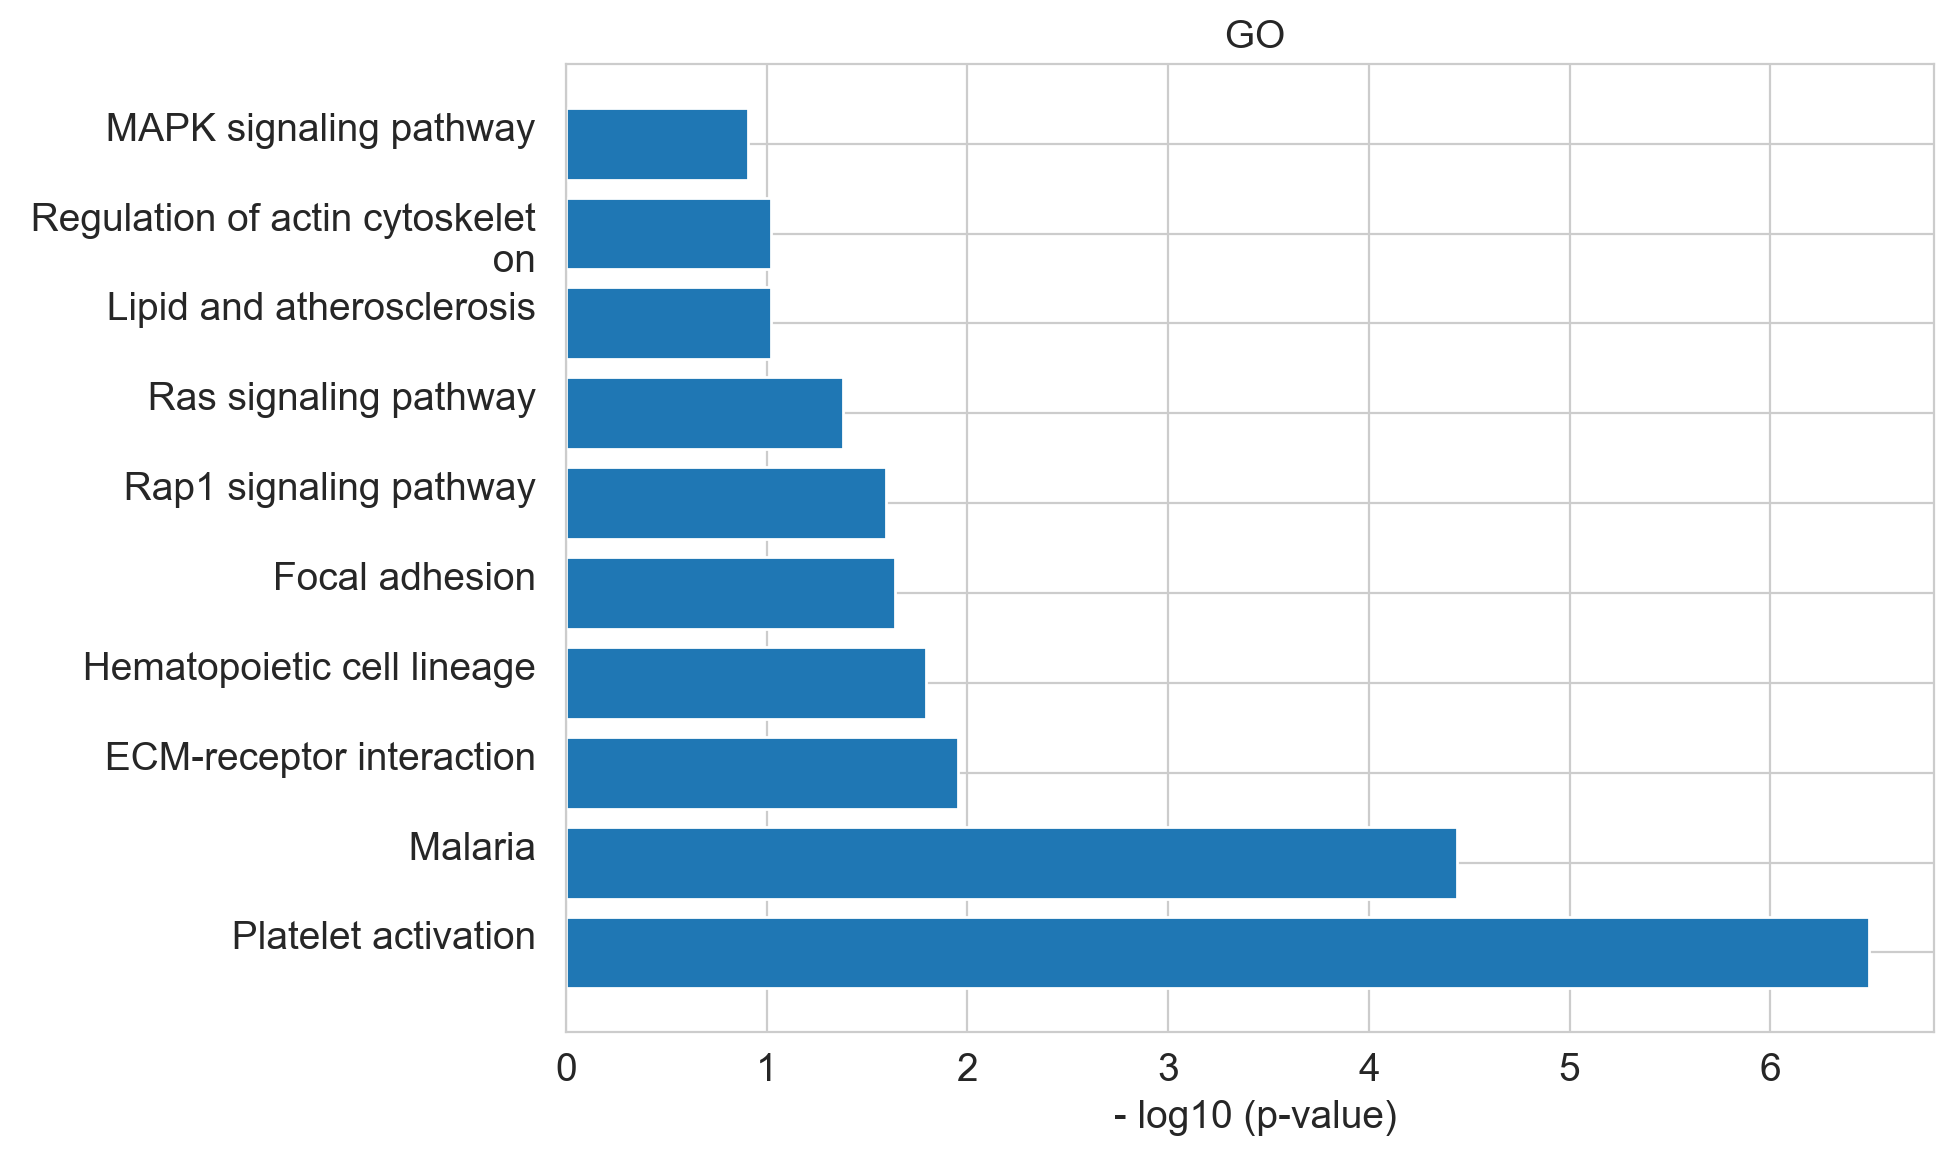

In [74]:
enrichment_results  =  gp.enrichr ( gene_list = 
    imk1_markers['names'] , gene_sets = [ 'GO_Biological_Process_2021' , 'KEGG_2021_Human' ], organism = 'human' , outdir = None , cutoff = 0.05 )
plt.figure(figsize=(10, 6))

# GO biological process
go_bp  =  enrichment_results.results [ enrichment_results.results [ 'Gene_set'] == 'GO_Biological_Process_2021' ] . head ( 10 ) 
plt.barh ( range ( len ( go_bp ) ) , -np.log10 ( go_bp [ 'Adjusted P-value' ])) 
plt.yticks ( range ( len ( go_bp )), [ term [ : 30 ] for term in go_bp [ 'Term' ] ]) 
plt.xlabel ( ' - log10 (p-value)' ) 
plt.title ( ' GO' ) 
plt. yticks ( range ( len ( go_bp )), [ " {} \n {} " . format ( term [: 30 ], term [ 30 : 60 ]) for term in go_bp [ 'Term' ]]) 
plt.tight_layout ()
      

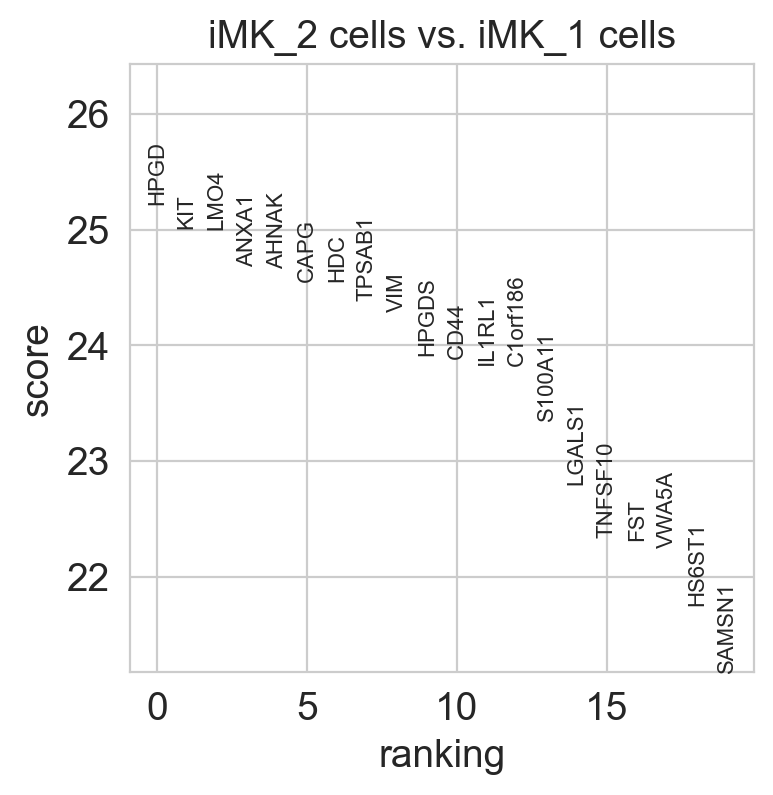

In [75]:
sc.tl.rank_genes_groups(
    adata, 
    groupby="celltype",       # group by cell type
    groups=["iMK_2 cells"],         # cluster to test (iMK-1)
    reference="iMK_1 cells",        # reference group (iMK-2)
    method="wilcoxon",        # common single-cell DE method (t-test, logreg etc. also possible)
    rankby_abs=True           # rank by absolute score (optional)
)

# DE results (genes up in iMK-1 vs iMK-2)
sc.pl.rank_genes_groups(adata, groups=["iMK_2 cells"], n_genes=20, sharey=False)

# Extract DE genes (up in iMK-1)
imk2_markers = sc.get.rank_genes_groups_df(adata, group="iMK_2 cells", log2fc_min=0.5, pval_cutoff=0.05)

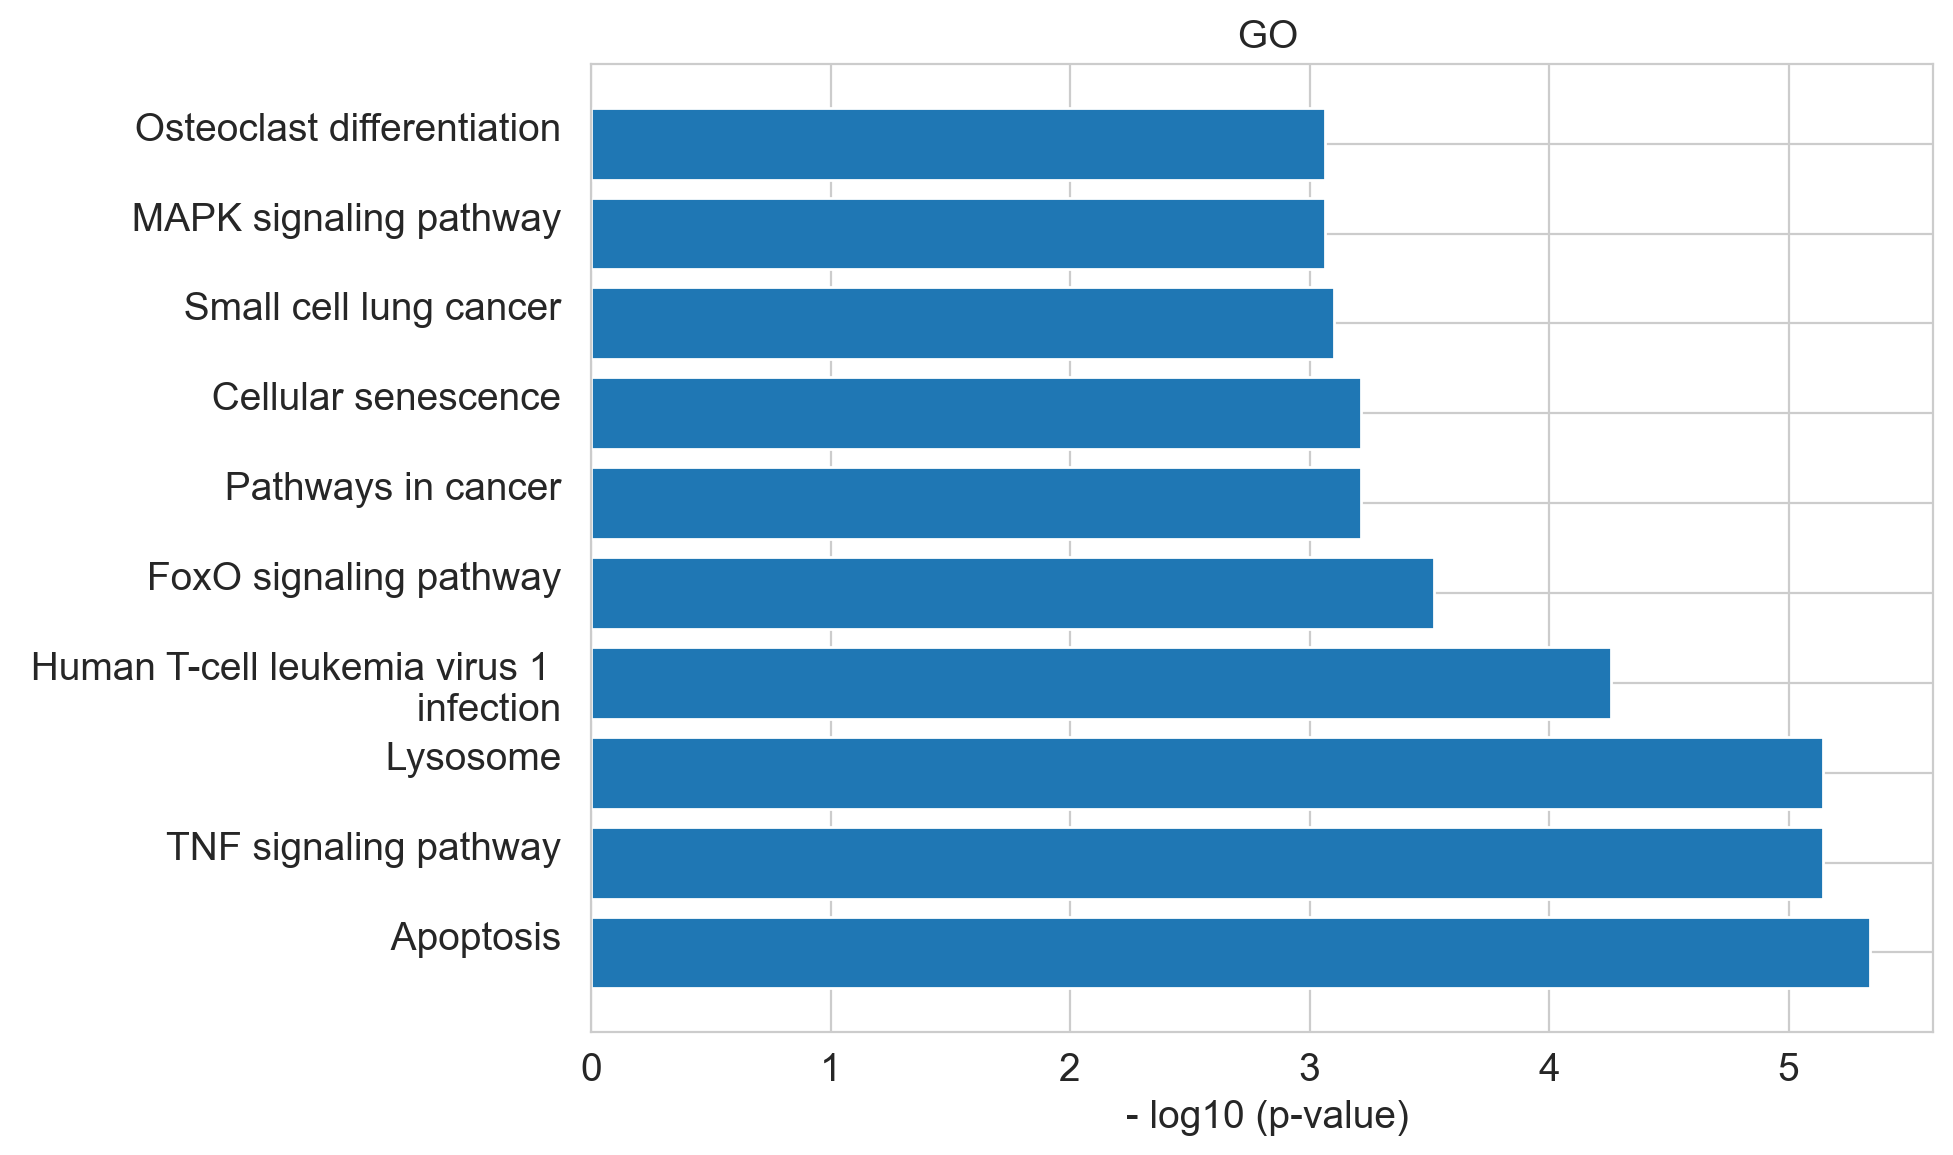

In [76]:
enrichment_results  =  gp.enrichr ( gene_list = 
    imk2_markers['names'] , gene_sets = [ 'GO_Biological_Process_2021' , 'KEGG_2021_Human' ], organism = 'human' , outdir = None , cutoff = 0.05 )
plt.figure(figsize=(10, 6))

# GO biological process
go_bp  =  enrichment_results.results [ enrichment_results.results [ 'Gene_set'] == 'GO_Biological_Process_2021' ] . head ( 10 ) 
plt.barh ( range ( len ( go_bp ) ) , -np.log10 ( go_bp [ 'Adjusted P-value' ])) 
plt.yticks ( range ( len ( go_bp )), [ term [ : 30 ] for term in go_bp [ 'Term' ] ]) 
plt.xlabel ( ' - log10 (p-value)' ) 
plt.title ( ' GO' ) 
plt. yticks ( range ( len ( go_bp )), [ " {} \n {} " . format ( term [: 30 ], term [ 30 : 60 ]) for term in go_bp [ 'Term' ]]) 
plt.tight_layout ()

In [ ]:
# Mean doublet_score of all cells
global_mean_doublet = adata.obs['doublet_score'].mean()
print(f"Mean doublet_score, all cells: {global_mean_doublet:.4f}")

# Mean doublet_score of the iMK_2 cluster
imk2_mean_doublet = adata.obs[adata.obs['celltype'] == 'iMK_2 cells']['doublet_score'].mean()
print(f"Mean doublet_score, iMK_2 cluster: {imk2_mean_doublet:.4f}")

Mean doublet_score, all cells: 0.0646
Mean doublet_score, iMK_2 cluster: 0.3239
